# CSE 4095 — Class 5
## Feature Engineering → Importance → Selection → Randomized Search
Protect the final test set throughout model development.

## 1. Load and inspect Auto MPG (Part 1)

**Goal:** understand the data before building a model.

One row describes a vehicle. The **target** is `mpg` (miles per gallon). A **feature** is an input we might use to predict that target. This is a regression task because the prediction is a numerical value.

We will load the data, inspect its structure, check missing values, and visualize MPG. We are not choosing engineered features or fitting a model yet.

The first code cell records Python and library versions. Numerical summaries are generated from each run's results, because small implementation differences between environments can affect forest scores and close rankings. The recorded versions describe the environment; they do not install or pin it.

In [90]:
import platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Record the environment for this execution; a seed alone does not pin versions.
library_versions = {
    "Python": platform.python_version(),
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "Matplotlib": matplotlib.__version__,
}
print("Execution environment")
for library, version in library_versions.items():
    print(f"{library}: {version}")

DATA_URL = "https://raw.githubusercontent.com/plotly/datasets/master/auto-mpg.csv"

# Pandas recognizes blank fields as missing. Also recognize "?" if present.
df = pd.read_csv(DATA_URL, na_values=["?"])

print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
print("Column names:", df.columns.tolist())
display(df.head())

Execution environment
Python: 3.13.2
NumPy: 2.2.4
pandas: 2.2.3
SciPy: 1.15.2
scikit-learn: 1.8.0
Matplotlib: 3.10.1
Rows: 398 | Columns: 7
Column names: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model-year']


,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
0,18.0,8,307.0,130.0,3504,12.0,70
1,15.0,8,350.0,165.0,3693,11.5,70
2,18.0,8,318.0,150.0,3436,11.0,70
3,16.0,8,304.0,150.0,3433,12.0,70
4,17.0,8,302.0,140.0,3449,10.5,70


### Read the structure

`df` is our DataFrame: a table with named columns.

- `shape` gives (number of rows, number of columns).
- `head()` shows the first five rows; it does not summarize the whole dataset.
- `info()` reports column types and counts of nonmissing values. `int64` and `float64` are numerical types; a float can also represent missing values as `NaN`.

Each displayed row contains one vehicle's measurements and MPG.

In [91]:
df.info()

print("\nMissing values per column:")
display(df.isna().sum().rename("missing_count").to_frame())

print("Rows with at least one missing value:")
display(df.loc[df.isna().any(axis=1)])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    396 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model-year    398 non-null    int64  
dtypes: float64(4), int64(3)
memory usage: 21.9 KB

Missing values per column:


,missing_count
mpg,0
cylinders,0
displacement,0
horsepower,2
weight,0
acceleration,0
model-year,0


Rows with at least one missing value:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
32,25.0,4,98.0,NaN,2046,19.0,71
126,21.0,6,200.0,NaN,2875,17.0,74


### Summarize the values

`describe()` reports the number of known values, mean, standard deviation, minimum, quartiles, and maximum for each numerical column. The 50% row is the median. The lower `count` for horsepower identifies its missing measurements.

We will leave missing values in place during this inspection. Any filling strategy used for modeling will learn its replacement values from training data only, and within each cross-validation training fold.

In [92]:
display(df.describe().round(2))

missing_counts = df.isna().sum()
missing_description = "; ".join(
    f"{column}: {int(count)} missing" for column, count in missing_counts.items() if count > 0
) or "No missing values"
display(Markdown(
    f"**Computed data interpretation:** There are **{len(df)} vehicle records**. "
    f"The target is **MPG**, a numerical outcome, so this is regression. "
    f"Original predictors: **{', '.join(df.columns.drop('mpg'))}**. "
    f"Missing values: **{missing_description}**. MPG ranges from "
    f"**{df['mpg'].min():.1f} to {df['mpg'].max():.1f}**, with median "
    f"**{df['mpg'].median():.1f}**."
))

,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
count,398.00,398.00,398.00,396.00,398.00,398.00,398.00
mean,23.51,5.45,193.43,104.19,2970.42,15.57,76.01
std,7.82,1.70,104.27,38.40,846.84,2.76,3.70
min,9.00,3.00,68.00,46.00,1613.00,8.00,70.00
25%,17.50,4.00,104.25,75.00,2223.75,13.82,73.00
50%,23.00,4.00,148.50,92.00,2803.50,15.50,76.00
75%,29.00,8.00,262.00,125.00,3608.00,17.18,79.00
max,46.60,8.00,455.00,230.00,5140.00,24.80,82.00


**Computed data interpretation:** There are **398 vehicle records**. The target is **MPG**, a numerical outcome, so this is regression. Original predictors: **cylinders, displacement, horsepower, weight, acceleration, model-year**. Missing values: **horsepower: 2 missing**. MPG ranges from **9.0 to 46.6**, with median **23.0**.

### MPG distribution

The histogram groups MPG values into ranges, with fuel economy on the horizontal axis and vehicle counts on the vertical axis. Most observations are in the lower and middle MPG ranges, with fewer very high-MPG vehicles and a tail toward higher fuel economy.

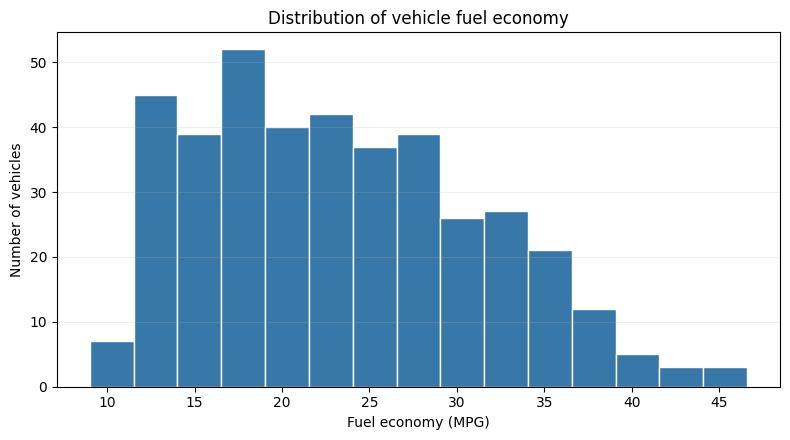

In [93]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df["mpg"], bins=15, color="#3778A8", edgecolor="white")
ax.set_title("Distribution of vehicle fuel economy")
ax.set_xlabel("Fuel economy (MPG)")
ax.set_ylabel("Number of vehicles")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

### Data interpretation

Each row represents a vehicle, and MPG is the numerical prediction target, making this a regression problem. The six original numerical columns are potential predictors. The inspection shows missing values in horsepower.

Replacing missing horsepower with zero would make it look like the vehicle has zero horsepower, which has a meaning of its own. Missing horsepower means the measurement is unknown. I use median imputation, with the median learned from each CV training fold, so validation rows do not influence the replacement values.

## 2. Define X/y and create one train/test split (Part 2)

**Goal:** reserve a final check before we start making modeling choices.

- `X` contains the six potential input features. `drop(columns="mpg")` makes a table without the target column; it does not change `df`.
- `y` contains the MPG values we want to predict.
- The training set is used for development, including cross-validation.
- The test set stays set aside until the final evaluation. We will not use it to choose engineered features, feature subsets, or hyperparameters.

`test_size=0.20` reserves about 20% of rows. `random_state=42` makes the random split reproducible when we rerun the same code on the same data; 42 is an arbitrary seed, not a setting chosen to improve the score.

We split before filling missing values. Later, any replacement values will be learned using only the training portion of each cross-validation fold.

In [94]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="mpg")
y = df["mpg"]

# Split inputs and targets together so each vehicle keeps its correct MPG.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
)

print(f"Training set: {len(X_train)} vehicles, {X_train.shape[1]} features")
print(f"Test set reserved: {len(X_test)} vehicles")
print("Target:", y.name)
print("Input features:", X.columns.tolist())
print("Keep this split fixed throughout the assignment.")

Training set: 318 vehicles, 6 features
Test set reserved: 80 vehicles
Target: mpg
Input features: ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model-year']
Keep this split fixed throughout the assignment.


### Why protect the test set?

The test set stops being a held-out test set once I use it to make decisions. Every time I check the test score and then change features, information from the test set leaks into my model-building process. I am effectively selecting the feature set that happens to do well on that particular test sample, including its noise and quirks. This can make the final score look better than the model's performance on new vehicles.

I create the test split before experimenting and use training-data cross-validation for development. The test set evaluates the choices fixed before final testing. The assignment-required initial inspection used all rows before splitting, but no modeling decision used the test rows.

## 3. Mean baseline + untuned Random Forest baseline (Part 3)

**Goal:** establish reference results before engineering features or tuning a model.

The **mean predictor** ignores vehicle features and predicts the average MPG learned from its training data for every vehicle. This asks: how well can we do without using the inputs at all?

An **untuned Random Forest** combines predictions from many decision trees. Each tree learns rules using vehicle features, and the forest averages their predictions. We will use the original six inputs, default forest settings, and `random_state=42`.

### How we measure errors

- **MAE:** average absolute difference between actual and predicted MPG. An MAE of 3 means errors average 3 MPG in magnitude, not that every prediction misses by 3. Lower is better. This is our primary comparison metric.
- **RMSE:** square the errors, average them, then take the square root. It is also in MPG units, but large errors have more influence. Lower is better.
- **R²:** compares squared errors with a constant prediction equal to the evaluation set's mean. A perfect result is 1; 0 matches that reference; negative values are possible. Higher is better. A mean predictor trained on different rows can have a negative validation R².

For example, actual MPG `[20, 30]` and predictions `[23, 25]` give absolute errors `[3, 5]`, so MAE is `(3 + 5) / 2 = 4` MPG. RMSE is `sqrt((9 + 25) / 2)`, about 4.12 MPG.

### Five-fold cross-validation uses only our 318 training vehicles

1. Shuffle the training rows reproducibly and divide them into five groups, called folds.
2. Fit a fresh model on four folds and evaluate predictions on the remaining fold.
3. Repeat until each fold has served as validation once.
4. Report the average errors and how much MAE varies across the five folds.

Both baselines use the same folds. In each fold, the mean predictor learns its average from that fold's training rows only.

For the forest, a **pipeline** first fills missing numerical values with column medians and then fits the model. Cross-validation fits this entire pipeline separately for each fold, so the median also comes only from that fold's training rows. We choose median filling as a simple baseline strategy, not as a claim that the missing horsepower is truly the median.

We will reuse this fixed CV procedure for later comparisons. The final 80 test vehicles are not involved.

In [95]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline

cv = KFold(n_splits=5, shuffle=True, random_state=42)

mean_baseline = DummyRegressor(strategy="mean")
mean_baseline.fit(X_train, y_train)
print(f"Mean predictor fitted on all training rows: {mean_baseline.constant_[0, 0]:.2f} MPG")
print("This fitted predictor gives the same MPG prediction for every vehicle.")

rf_baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestRegressor(random_state=42)),
])

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

baseline_models = {
    "Mean predictor": mean_baseline,
    "Untuned Random Forest": rf_baseline,
}

Mean predictor fitted on all training rows: 23.61 MPG
This fitted predictor gives the same MPG prediction for every vehicle.


### Run the comparison

`cross_validate()` creates fresh fitted copies for the folds, even though we fitted the mean predictor above to display the overall training mean.

Scikit-learn uses negative error scores so that a larger score always means better performance. We multiply MAE and RMSE scores by −1 to report ordinary positive errors. R² keeps its original sign.

The returned keys `test_mae`, `test_rmse`, and `test_r2` refer to each CV validation fold. The word `test` in these library keys does **not** refer to our reserved `X_test` or `y_test`.

The summary reports averages of the five fold metrics; its standard deviation describes the spread of the five MAEs. It is not a confidence interval.

In [96]:
baseline_cv_results = {}
summary_rows = []
fold_mae = {}

for name, model in baseline_models.items():
    results = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring=scoring, error_score="raise",
    )
    baseline_cv_results[name] = results
    mae = -results["test_mae"]
    rmse = -results["test_rmse"]
    fold_mae[name] = mae
    summary_rows.append({
        "Model": name,
        "Mean CV MAE (MPG)": mae.mean(),
        "CV MAE Std (MPG)": mae.std(),
        "Mean CV RMSE (MPG)": rmse.mean(),
        "Mean CV R2": results["test_r2"].mean(),
    })

baseline_summary = pd.DataFrame(summary_rows).set_index("Model")
fold_mae_table = pd.DataFrame(fold_mae, index=range(1, 6))
fold_mae_table.index.name = "Validation fold"

print("Baseline comparison: averages across five validation folds")
display(baseline_summary.round(3))
print("MAE for each fold (MPG)")
display(fold_mae_table.round(3))

display(Markdown(
    f"**Computed baseline summary:** The untuned forest has mean CV MAE "
    f"**{fold_mae['Untuned Random Forest'].mean():.2f} MPG**, compared with "
    f"**{fold_mae['Mean predictor'].mean():.2f} MPG** for the fold-trained mean predictor. "
    f"The forest's MAE is lower in "
    f"**{int((fold_mae['Untuned Random Forest'] < fold_mae['Mean predictor']).sum())} "
    f"of {cv.get_n_splits()} folds**. MAE measures average absolute error, not the error of every vehicle."
))

Baseline comparison: averages across five validation folds


,Mean CV MAE (MPG),CV MAE Std (MPG),Mean CV RMSE (MPG),Mean CV R2
Model,,,,
Mean predictor,6.702,0.452,7.923,-0.017
Untuned Random Forest,2.005,0.129,2.926,0.858


MAE for each fold (MPG)


,Mean predictor,Untuned Random Forest
Validation fold,,
1,7.025,2.130
2,6.747,2.024
3,6.359,1.779
4,6.059,2.128
5,7.321,1.966


**Computed baseline summary:** The untuned forest has mean CV MAE **2.01 MPG**, compared with **6.70 MPG** for the fold-trained mean predictor. The forest's MAE is lower in **5 of 5 folds**. MAE measures average absolute error, not the error of every vehicle.

### Baseline interpretation

I need the untuned Random Forest baseline as a control so I can tell whether a later improvement comes from engineered features rather than switching models, tuning hyperparameters, or changing the split. Keeping the same model class, settings, data split, and metric gives a fair reference for judging a new score. The forest substantially outperforms the mean predictor, which shows what can be gained by using the vehicle features. Random Forests already capture some nonlinearities and interactions, so ratios may add little benefit.

A small decrease in CV MAE is an observed gain, not proof of a reliable improvement. Paired fold differences compare the models on the same validation vehicles and show how consistently a change helps. Their spread is descriptive rather than a significance test, and a baseline comparison alone cannot rule out leakage.

## 4. Initial feature engineering (Parts 4–5)

**Goal:** propose meaningful representations, choose them with a rationale, then evaluate them fairly.

A forest can learn relationships between inputs, but a ratio may express a useful relationship more directly. Engineered features do not add new measurements; they reorganize information we already have. Improvement is a hypothesis to test, not a guarantee.

### Selected features — all four candidates

| Candidate | Formula | Interpretation and hypothesis |
|---|---|---|
| `power_to_weight` | `horsepower / weight` | Power relative to vehicle weight. Similar horsepower can represent different power relative to the load being moved. This balance might help distinguish MPG behavior. |
| `displacement_per_cylinder` | `displacement / cylinders` | Average engine displacement per cylinder. It expresses engine size relative to cylinder count, which might distinguish engine configurations with different MPG behavior. |
| `power_per_displacement` | `horsepower / displacement` | Power relative to engine displacement. Vehicles with similar engine size can produce different power; this relationship might be relevant to MPG. It is not a direct measurement of fuel efficiency. |
| `weight_per_cylinder` | `weight / cylinders` | Vehicle weight relative to cylinder count. It is a rough measure of vehicle load relative to this aspect of engine configuration and might help predict MPG. It does not imply that each cylinder carries an equal share of the weight. |

These are candidate associations, not causal claims. They share raw inputs and may be correlated or redundant. Cross-validation will decide whether adding the chosen features helps this model.

**Simple example:** Two vehicles both have 100 horsepower, but one weighs 2,000 and the other 4,000 in the dataset's weight units. Their power-to-weight ratios are 0.05 and 0.025: the first has twice the power per unit of weight. This does not by itself tell us which one has higher MPG.

### Feature choice and initial hypotheses

**Choice:** Test all four candidate features, exceeding the assignment minimum of three. The table records each formula and rationale.

**Initial predictions:**

- Power-to-weight: I expect higher values to be associated with lower MPG, with the strongest negative relationship of the four.
- Displacement per cylinder: I expect this engine-size ratio to have a negative relationship with MPG.
- Power per displacement: I expect a weaker negative relationship.
- Weight per cylinder: I expect the weakest negative relationship.

These are hypotheses, not findings. "Negative" describes an expected association, not proof that changing a feature causes MPG to change. The ratios use different scales, so comparing raw slope magnitudes would not fairly rank them. Predictive usefulness and the direction of an association are different questions. This first CV experiment tests all four features as a group, not these individual directional predictions.

The implementation uses training data, checks denominator validity, and preserves missing values for fold-specific imputation. We will compare original inputs with original plus engineered inputs using the same untuned forest and CV folds. The final test set stays reserved.


In [97]:
def engineer_features(data):
    """Add the four chosen ratios without learning values from other rows."""
    result = data.copy()

    # Nonpositive denominators are invalid for these ratios; leave them missing.
    safe_weight = result["weight"].where(result["weight"] > 0)
    safe_cylinders = result["cylinders"].where(result["cylinders"] > 0)
    safe_displacement = result["displacement"].where(result["displacement"] > 0)

    result["power_to_weight"] = result["horsepower"] / safe_weight
    result["displacement_per_cylinder"] = result["displacement"] / safe_cylinders
    result["power_per_displacement"] = result["horsepower"] / safe_displacement
    result["weight_per_cylinder"] = result["weight"] / safe_cylinders
    return result


# Develop features on training data only. Keep the final test set reserved.
X_train_engineered = engineer_features(X_train)
engineered_columns = [
    "power_to_weight", "displacement_per_cylinder",
    "power_per_displacement", "weight_per_cylinder",
]

print(f"Original inputs: {X_train.shape[1]} | Original + engineered: {X_train_engineered.shape[1]}")
print("Nonpositive denominator counts in training data:")
display(X_train[["weight", "cylinders", "displacement"]].le(0).sum().to_frame("count"))
print("Examples of the four new features:")
display(X_train_engineered[engineered_columns].head().round(4))
print("Missing values in the new features:")
display(X_train_engineered[engineered_columns].isna().sum().to_frame("missing_count"))

Original inputs: 6 | Original + engineered: 10
Nonpositive denominator counts in training data:


,count
weight,0
cylinders,0
displacement,0


Examples of the four new features:


,power_to_weight,displacement_per_cylinder,power_per_displacement,weight_per_cylinder
3,0.0437,38.00,0.4934,429.125
18,0.0413,24.25,0.9072,532.500
376,0.0336,22.75,0.7473,506.250
248,0.0333,22.75,0.6593,450.000
177,0.0353,28.75,0.8261,673.500


Missing values in the new features:


,missing_count
power_to_weight,1
displacement_per_cylinder,0
power_per_displacement,1
weight_per_cylinder,0


### Directional associations with MPG

This retrospective descriptive check uses only the original training rows and does not determine any feature, tuning, or model choice. It compares the initial directional hypotheses with the observed training associations.

Spearman correlation compares monotonic associations on a common scale. Missing pairs are omitted, rather than imputed from other rows. These are marginal associations with MPG, not causal effects, partial effects with other inputs fixed, or tests of a ratio's incremental predictive benefit.

In [98]:
directional_correlations = X_train_engineered[engineered_columns].corrwith(
    y_train, method="spearman"
)
directional_summary = directional_correlations.to_frame("Training Spearman with MPG")
directional_summary["Recorded prediction"] = [
    "Negative; strongest of four", "Negative", "Negative; weaker", "Negative; weakest",
]
directional_summary["Observed association"] = [
    "positive" if value > 0 else "negative" if value < 0 else "zero"
    for value in directional_correlations
]
directional_summary["Rank by absolute association"] = (
    directional_correlations.abs().rank(ascending=False, method="min").astype(int)
)
display(directional_summary.round(3))
display(Markdown(
    f"**Review of my predictions:** Displacement per cylinder has correlation "
    f"**{directional_correlations['displacement_per_cylinder']:+.3f}** with MPG, "
    f"consistent with my negative prediction; power-to-weight is "
    f"**{directional_correlations['power_to_weight']:+.3f}**, ranked "
    f"**{directional_summary.loc['power_to_weight', 'Rank by absolute association']} of four** "
    f"by absolute association, so my strongest-negative prediction is not supported. "
    f"Power per displacement is "
    f"**{directional_correlations['power_per_displacement']:+.3f}**, "
    f"{'opposite to' if directional_correlations['power_per_displacement'] > 0 else 'consistent with'} "
    f"my negative prediction, while weight per cylinder is "
    f"**{directional_correlations['weight_per_cylinder']:+.3f}**, close to zero. "
    f"This closes the descriptive question; the controlled CV comparisons "
    f"separately address whether these ratios help prediction."
))

,Training Spearman with MPG,Recorded prediction,Observed association,Rank by absolute association
power_to_weight,-0.201,Negative; strongest of four,negative,3
displacement_per_cylinder,-0.806,Negative,negative,1
power_per_displacement,0.609,Negative; weaker,positive,2
weight_per_cylinder,-0.018,Negative; weakest,negative,4


**Review of my predictions:** Displacement per cylinder has correlation **-0.806** with MPG, consistent with my negative prediction; power-to-weight is **-0.201**, ranked **3 of four** by absolute association, so my strongest-negative prediction is not supported. Power per displacement is **+0.609**, opposite to my negative prediction, while weight per cylinder is **-0.018**, close to zero. This closes the descriptive question; the controlled CV comparisons separately address whether these ratios help prediction.

### Why these calculations can happen before CV

Each formula uses only values from the same vehicle. It does not learn a mean, median, threshold, or coefficient from other rows. We can therefore compute these fixed ratios before cross-validation without sharing learned information between folds.

Missing horsepower remains missing in horsepower-based ratios. We do not replace it with zero. During CV, the pipeline's imputer will learn a separate median for each raw or engineered column from that fold's training portion.

The function retains all original inputs and adds four columns, giving ten inputs in total. It makes a copy so the original six-feature representation remains available for comparison.

## 5. Original vs. engineered representation (Part 6)

**Question:** Does adding the four selected ratios improve the untuned forest's predictions?

- **Model A:** the original six inputs.
- **Model B:** the original six inputs plus our four ratios.
- **Fixed controls:** the same Random Forest defaults, forest seed, median-imputation strategy, 318 training vehicles, five CV folds, and MAE scoring.

We reuse Model A's saved fold errors from Section 3. `cross_val_score` will fit fresh copies of the same pipeline for Model B. Adding columns also changes the model's available splitting choices; that is part of the representation experiment.

Both models evaluate the same vehicles within each validation fold. The per-fold difference is **engineered MAE minus original MAE**: a negative difference favors the engineered representation. The fold standard deviation describes variability, not a significance test.

**Practical interpretation:** An absolute mean MAE difference below about **0.05 MPG**—roughly 2.5% of an MAE near 2 MPG—is treated as practically negligible for this project. I chose this reporting yardstick after the initial results, so it is retrospective rather than a prespecified threshold or a statistical significance rule. This yardstick guides reporting rather than automatically choosing the fewest columns. Paired fold differences provide context for the comparison; their descriptive spread is not a confidence interval.

In [99]:
from sklearn.model_selection import cross_val_score

original_mae = -baseline_cv_results["Untuned Random Forest"]["test_mae"]
engineered_mae = -cross_val_score(
    rf_baseline, X_train_engineered, y_train,
    cv=cv, scoring="neg_mean_absolute_error", error_score="raise",
)

engineering_comparison = pd.DataFrame([
    {
        "Feature set": "Original",
        "Number of features": X_train.shape[1],
        "Mean CV MAE (MPG)": original_mae.mean(),
        "CV MAE Std (MPG)": original_mae.std(),
    },
    {
        "Feature set": "Original + engineered",
        "Number of features": X_train_engineered.shape[1],
        "Mean CV MAE (MPG)": engineered_mae.mean(),
        "CV MAE Std (MPG)": engineered_mae.std(),
    },
]).set_index("Feature set")

engineering_fold_comparison = pd.DataFrame({
    "Original MAE": original_mae,
    "Engineered MAE": engineered_mae,
    "Engineered minus original": engineered_mae - original_mae,
}, index=range(1, 6))
engineering_fold_comparison.index.name = "Validation fold"

display(engineering_comparison.round(3))
display(engineering_fold_comparison.round(3))
print(f"Mean MAE reduction: {original_mae.mean() - engineered_mae.mean():.4f} MPG")
print("Positive reduction favors engineered features; negative reduction favors original features.")

practical_mae_difference = 0.05
engineering_differences = engineered_mae - original_mae
display(Markdown(
    f"**Computed engineering summary:** Original inputs: **{original_mae.mean():.2f} MPG**; "
    f"original plus ratios: **{engineered_mae.mean():.2f} MPG**. "
    f"The mean paired difference (engineered minus original) is "
    f"**{engineering_differences.mean():+.4f} MPG**, with paired SD "
    f"**{engineering_differences.std(ddof=0):.4f} MPG**. "
    f"The engineered set improves **{int((engineering_differences < 0).sum())} "
    f"of {len(engineering_differences)} folds**. "
    f"The absolute mean difference is "
    f"{'below' if abs(engineering_differences.mean()) < practical_mae_difference else 'at or above'} "
    f"the practical reporting yardstick."
))

,Number of features,Mean CV MAE (MPG),CV MAE Std (MPG)
Feature set,,,
Original,6,2.005,0.129
Original + engineered,10,2.004,0.092


,Original MAE,Engineered MAE,Engineered minus original
Validation fold,,,
1,2.130,2.057,-0.072
2,2.024,2.101,0.077
3,1.779,1.832,0.053
4,2.128,2.023,-0.105
5,1.966,2.005,0.039


Mean MAE reduction: 0.0018 MPG
Positive reduction favors engineered features; negative reduction favors original features.


**Computed engineering summary:** Original inputs: **2.01 MPG**; original plus ratios: **2.00 MPG**. The mean paired difference (engineered minus original) is **-0.0018 MPG**, with paired SD **0.0727 MPG**. The engineered set improves **2 of 5 folds**. The absolute mean difference is below the practical reporting yardstick.

### Interpretation of the engineered representation

As a group, I conclude that the four engineered features do not provide a meaningful improvement. Mean CV MAE stayed essentially the same, and the small average gain is negligible compared with the paired fold differences and the project's reporting yardstick. The engineered representation helped some folds and hurt others, so its slightly lower standard deviation is not enough to claim a reliable advantage. I would not add these four features just for prediction accuracy because they add complexity without demonstrated benefit. The original six inputs may already let the forest capture similar relationships, but that explanation has not been established.

This comparison does not tell me whether each individual feature is useful. The four were added together, so the result is their combined effect; some could help while others hurt or overlap. Testing them one at a time or removing one feature and retraining under the same CV controls would examine their incremental value. Feature ablation is different from LeaveOneOut CV over vehicles. Prediction error also does not tell me the direction of a feature's association with MPG. An experiment showing no benefit or worse performance is still useful evidence.

## 6. Built-in Random Forest feature importance (Parts 7–8)

**Question:** Which inputs does the forest use to reduce training prediction error?

A regression tree repeatedly splits vehicles into groups. With the default squared-error criterion, built-in importance credits a feature for the weighted reductions in squared-error impurity achieved by its splits, averaged over the forest and normalized. The importances sum to 1.

An importance of 0.30 means about 30% of this normalized training splitting credit. It does not mean that the feature explains 30% of MPG or causes a 30% change in MPG.

We fit a fresh copy of the engineered pipeline on all training rows. We retain the ten-feature candidate representation for this diagnostic analysis; this does not override our conclusion that adding all four ratios did not meaningfully improve mean CV MAE.

Built-in importance can favor features with many possible split values. Correlated features can share credit. It describes this fitted model, not a feature's universal value.

,Built-in importance (all training rows)
displacement,0.4133
horsepower,0.1655
cylinders,0.1162
weight,0.1053
model-year,0.0999
weight_per_cylinder,0.0298
displacement_per_cylinder,0.0237
acceleration,0.0188
power_to_weight,0.0137
power_per_displacement,0.0137


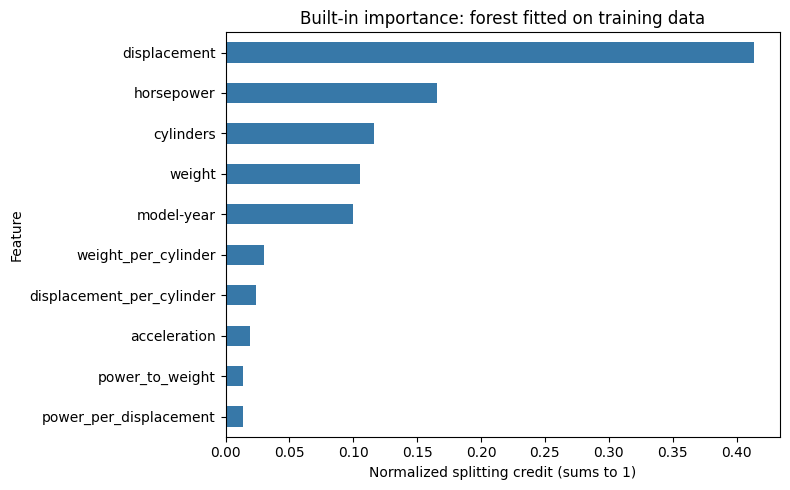

**Computed built-in interpretation:** The full-training forest gives most splitting credit to **displacement** and least to **power_per_displacement**. The highest-ranked engineered feature is **weight_per_cylinder**, rank **6 of 10**. These are training-split credits, not evidence of causal effects.

In [100]:
from sklearn.base import clone

engineered_model = clone(rf_baseline).fit(X_train_engineered, y_train)
feature_names = engineered_model.named_steps["imputer"].get_feature_names_out()
builtin_importance = pd.Series(
    engineered_model.named_steps["rf"].feature_importances_,
    index=feature_names,
    name="Built-in importance (all training rows)",
).sort_values(ascending=False)

display(builtin_importance.to_frame().round(4))

fig, ax = plt.subplots(figsize=(8, 5))
builtin_importance.sort_values().plot.barh(ax=ax, color="#3778A8")
ax.set_title("Built-in importance: forest fitted on training data")
ax.set_xlabel("Normalized splitting credit (sums to 1)")
ax.set_ylabel("Feature")
fig.tight_layout()
plt.show()

builtin_ranks = builtin_importance.rank(ascending=False, method="min").astype(int)
highest_engineered_builtin = builtin_importance.loc[engineered_columns].idxmax()
display(Markdown(
    f"**Computed built-in interpretation:** The full-training forest gives most "
    f"splitting credit to **{builtin_importance.idxmax()}** and least to "
    f"**{builtin_importance.idxmin()}**. The highest-ranked engineered feature is "
    f"**{highest_engineered_builtin}**, rank "
    f"**{builtin_ranks.loc[highest_engineered_builtin]} of {len(builtin_importance)}**. "
    f"These are training-split credits, not evidence of causal effects."
))

## 7. Permutation importance on CV validation folds (Part 9)

**Question:** How much worse does a fitted model predict when one feature's values are shuffled?

For each of our same five training-data CV folds:

1. Fit a fresh pipeline on four folds, including learning imputation medians there.
2. Measure predictions on the remaining validation fold.
3. Shuffle one validation feature at a time and measure the change in MAE, without retraining the model.
4. Repeat each shuffle ten times, then average its MAE increases.

We average the five fold means. With `scoring="neg_mean_absolute_error"`, the returned importance is shuffled MAE minus original MAE, so positive values mean worse errors after shuffling. **Do not negate these returned importances.**

For example, an importance of +0.5 MPG means shuffling that column increased MAE by 0.5 MPG on average. A value close to zero means little measured change for these models. A negative value means shuffling slightly improved error; it does not automatically prove that dropping and retraining without the feature would help.

We also collect built-in importances from these five fitted forests so we can compare rankings from the same model fits. The final 80-vehicle test set remains reserved.

Completed importance analysis for validation fold 1/5
Completed importance analysis for validation fold 2/5
Completed importance analysis for validation fold 3/5
Completed importance analysis for validation fold 4/5
Completed importance analysis for validation fold 5/5


,Mean MAE increase (MPG),Std across fold means (MPG)
model-year,1.5479,0.1705
displacement,1.1789,0.2895
horsepower,0.9375,0.2709
weight,0.7993,0.1199
cylinders,0.3811,0.2854
displacement_per_cylinder,0.0880,0.0355
weight_per_cylinder,0.0782,0.1002
power_per_displacement,0.0568,0.0254
acceleration,0.0516,0.0276
power_to_weight,0.0216,0.0206


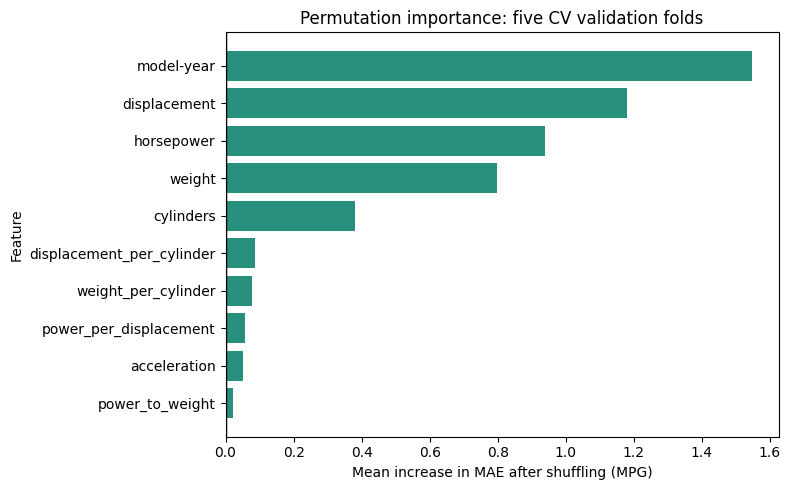

**Computed permutation interpretation:** The largest mean validation MAE increase is for **model-year**. The three lowest-ranked features are **power_per_displacement, acceleration, power_to_weight**. Their low marginal scores suggest controlled ablations, not automatic removal.

In [101]:
import numpy as np
from sklearn.inspection import permutation_importance

permutation_fold_rows = []
builtin_fold_rows = []

for fold, (fit_indices, val_indices) in enumerate(cv.split(X_train_engineered), start=1):
    X_fit = X_train_engineered.iloc[fit_indices]
    y_fit = y_train.iloc[fit_indices]
    X_val = X_train_engineered.iloc[val_indices]
    y_val = y_train.iloc[val_indices]

    fold_model = clone(rf_baseline).fit(X_fit, y_fit)
    result = permutation_importance(
        fold_model, X_val, y_val,
        scoring="neg_mean_absolute_error",
        n_repeats=10, random_state=42 + fold, n_jobs=1,
    )
    permutation_fold_rows.append(result.importances_mean)
    builtin_fold_rows.append(fold_model.named_steps["rf"].feature_importances_)
    print(f"Completed importance analysis for validation fold {fold}/5")

permutation_by_fold = pd.DataFrame(
    permutation_fold_rows, columns=X_train_engineered.columns, index=range(1, 6),
)
builtin_by_fold = pd.DataFrame(
    builtin_fold_rows, columns=X_train_engineered.columns, index=range(1, 6),
)
permutation_table = pd.DataFrame({
    "Mean MAE increase (MPG)": permutation_by_fold.mean(),
    "Std across fold means (MPG)": permutation_by_fold.std(ddof=0),
}).sort_values("Mean MAE increase (MPG)", ascending=False)

display(permutation_table.round(4))

plot_data = permutation_table.sort_values("Mean MAE increase (MPG)")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_data.index, plot_data["Mean MAE increase (MPG)"], color="#27917D")
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Permutation importance: five CV validation folds")
ax.set_xlabel("Mean increase in MAE after shuffling (MPG)")
ax.set_ylabel("Feature")
fig.tight_layout()
plt.show()

display(Markdown(
    f"**Computed permutation interpretation:** The largest mean validation MAE "
    f"increase is for **{permutation_table.index[0]}**. The three lowest-ranked "
    f"features are **{', '.join(permutation_table.index[-3:].tolist())}**. "
    f"Their low marginal scores suggest controlled ablations, not automatic removal."
))

## 8. Compare importance rankings (Parts 9–10)

Built-in importance asks about training split credit. Permutation importance asks about validation prediction error after disrupting a column. They use different units, so compare their rankings rather than their numerical magnitudes.

For a comparison using the same five forest fits, the table below averages built-in importances from those CV forests alongside their validation permutation importances. The full-training forest's built-in chart above is another view and may rank features slightly differently.

Correlated inputs can substitute for one another, so a feature can receive low importance even when it contains useful information. Shuffling a raw or engineered feature separately also breaks its relationships with other columns, including the formula linking a ratio to its raw inputs. Interpret these as model diagnostics, not as realistic interventions on a vehicle.

The reported permutation standard deviation is the spread of five fold means, each based on ten shuffles. It is descriptive, not a confidence interval or significance test. Neither importance method establishes the sign of a relationship, causation, or the effect of removing and retraining without a feature.

In [102]:
importance_comparison = pd.DataFrame({
    "Mean CV built-in importance": builtin_by_fold.mean(),
    "Mean validation MAE increase (MPG)": permutation_by_fold.mean(),
})
importance_comparison["Built-in rank"] = importance_comparison[
    "Mean CV built-in importance"
].rank(ascending=False, method="min").astype(int)
importance_comparison["Permutation rank"] = importance_comparison[
    "Mean validation MAE increase (MPG)"
].rank(ascending=False, method="min").astype(int)
importance_comparison["Engineered feature"] = importance_comparison.index.isin(engineered_columns)
importance_comparison = importance_comparison.sort_values("Permutation rank")
display(importance_comparison.round(4))

year_importance = importance_comparison.loc["model-year"]
display(Markdown(
    f"**Computed importance comparison:** Model year has built-in rank "
    f"**{int(year_importance['Built-in rank'])}** and permutation rank "
    f"**{int(year_importance['Permutation rank'])}**. "
    f"Shuffling it raises validation MAE by "
    f"**{year_importance['Mean validation MAE increase (MPG)']:.2f} MPG** on average."
))

training_distinct_values = X_train.nunique()
display(training_distinct_values.to_frame("Distinct observed training values"))
display(Markdown(
    f"**Possible explanation to investigate:** Model year has "
    f"**{int(training_distinct_values['model-year'])}** distinct training values, "
    f"versus **{int(training_distinct_values[['displacement', 'horsepower', 'acceleration', 'weight']].min())}–"
    f"{int(training_distinct_values[['displacement', 'horsepower', 'acceleration', 'weight']].max())}** "
    f"for displacement, horsepower, acceleration, and weight. Built-in importance "
    f"can favor inputs offering more possible split points. This is a plausible "
    f"contributor to the rank gap, not a demonstrated explanation of it."
))

,Mean CV built-in importance,Mean validation MAE increase (MPG),Built-in rank,Permutation rank,Engineered feature
model-year,0.1060,1.5479,5,1,False
displacement,0.3284,1.1789,1,2,False
horsepower,0.1667,0.9375,3,3,False
weight,0.1696,0.7993,2,4,False
cylinders,0.1353,0.3811,4,5,False
displacement_per_cylinder,0.0160,0.0880,8,6,True
weight_per_cylinder,0.0298,0.0782,6,7,True
power_per_displacement,0.0145,0.0568,10,8,True
acceleration,0.0184,0.0516,7,9,False
power_to_weight,0.0154,0.0216,9,10,True


**Computed importance comparison:** Model year has built-in rank **5** and permutation rank **1**. Shuffling it raises validation MAE by **1.55 MPG** on average.

,Distinct observed training values
cylinders,5
displacement,78
horsepower,89
weight,286
acceleration,90
model-year,13


**Possible explanation to investigate:** Model year has **13** distinct training values, versus **78–286** for displacement, horsepower, acceleration, and weight. Built-in importance can favor inputs offering more possible split points. This is a plausible contributor to the rank gap, not a demonstrated explanation of it.

### Interpretation and proposed ablation

The model year result surprises me most. Built-in importance ranked it relatively low, yet permuting it produced the largest increase in validation MAE. This suggests that the fitted forests rely heavily on model year for validation predictions, while impurity-based importance gives it less training-split credit. Its usefulness may be spread across smaller splits, involve interactions, or share information with other inputs. Model year also has fewer distinct training values than displacement, horsepower, acceleration, and weight, making the preference of impurity importance for more possible split points another plausible contributor. These are hypotheses; the rank gap alone does not reveal its cause.

Before removing power-to-weight, I would run a controlled ablation under the same CV folds and forest settings. Comparing all ten inputs with the nine without the ratio tests its value given the other engineered features. Comparing the original six with those six plus the ratio tests whether it helps on its own. Repeated CV can check sensitivity to partitions, and paired fold differences matter because the average effect may be tiny. A low marginal permutation rank alone does not justify deletion when correlated features can substitute for one another. Grouped or conditional permutation importance could be a future investigation, but those analyses were not performed.

### Training-only correlations and overlapping information

Spearman correlation describes pairwise monotonic association. This table uses observed training values, with missing pairs omitted by pandas. It does not use the target or final test rows.

Strong relationships between some ratios and raw inputs support hypotheses about overlapping information. Power-to-weight has a relatively strong negative association with acceleration, a moderate positive association with horsepower, and little monotonic association with weight in these training rows. Because acceleration is a retained original input, overlap with it is a plausible explanation to investigate.

Pairwise correlation alone does not prove predictive redundancy or rule out nonlinear or multivariable overlap. The ablation's predictive result therefore stands separately from an unproven explanation of why it occurred. Neither correlation nor model importance establishes causation.

In [103]:
training_spearman = X_train_engineered.corr(method="spearman")
display(training_spearman.round(2))

correlation_pairs = [
    ("displacement_per_cylinder", "displacement"),
    ("power_per_displacement", "displacement"),
    ("power_to_weight", "horsepower"),
    ("power_to_weight", "weight"),
    ("power_to_weight", "acceleration"),
]
for first, second in correlation_pairs:
    print(f"Spearman({first}, {second}) = {training_spearman.loc[first, second]:+.3f}")

cylinder_rank = int(importance_comparison.loc["cylinders", "Permutation rank"])
display(Markdown(
    f"**Computed context for the engineering-before-selection example:** Cylinders "
    f"has permutation rank **{cylinder_rank} of {len(importance_comparison)}**. "
    f"The example of discarding a low-ranked raw ingredient is hypothetical."
))

,cylinders,displacement,horsepower,weight,acceleration,model-year,power_to_weight,displacement_per_cylinder,power_per_displacement,weight_per_cylinder
cylinders,1.00,0.91,0.80,0.87,-0.44,-0.36,0.13,0.78,-0.75,-0.33
displacement,0.91,1.00,0.86,0.94,-0.46,-0.31,0.13,0.95,-0.79,-0.02
horsepower,0.80,0.86,1.00,0.87,-0.63,-0.41,0.47,0.81,-0.44,0.06
weight,0.87,0.94,0.87,1.00,-0.37,-0.29,0.04,0.89,-0.72,0.16
acceleration,-0.44,-0.46,-0.63,-0.37,1.00,0.27,-0.70,-0.42,0.07,0.17
model-year,-0.36,-0.31,-0.41,-0.29,0.27,1.00,-0.32,-0.29,0.13,0.15
power_to_weight,0.13,0.13,0.47,0.04,-0.70,-0.32,1.00,0.09,0.39,-0.19
displacement_per_cylinder,0.78,0.95,0.81,0.89,-0.42,-0.29,0.09,1.00,-0.77,0.15
power_per_displacement,-0.75,-0.79,-0.44,-0.72,0.07,0.13,0.39,-0.77,1.00,0.14
weight_per_cylinder,-0.33,-0.02,0.06,0.16,0.17,0.15,-0.19,0.15,0.14,1.00


Spearman(displacement_per_cylinder, displacement) = +0.954
Spearman(power_per_displacement, displacement) = -0.790
Spearman(power_to_weight, horsepower) = +0.471
Spearman(power_to_weight, weight) = +0.043
Spearman(power_to_weight, acceleration) = -0.701


**Computed context for the engineering-before-selection example:** Cylinders has permutation rank **5 of 10**. The example of discarding a low-ranked raw ingredient is hypothetical.

## 9. Feature-selection experiment (Part 11)

**Goal:** use importance to propose feature subsets, then compare retrained models rather than automatically deleting low-ranked inputs.

### Hypotheses and candidate subsets, specified before this subset comparison

| Candidate | Inputs | Reason to test |
|---|---|---|
| All 10 | Original six + all four ratios | Full candidate reference. |
| All minus power-to-weight | Nine inputs | The proposed ablation tests whether this low-ranked ratio adds value given the other nine. |
| Original 6 | Original inputs only | Simpler reference with essentially the same prior mean CV MAE. |
| Original + power-to-weight | Seven inputs | The proposed addition test asks whether the ratio helps without the other three engineered ratios. |
| Top 4 permutation | Model year, displacement, horsepower, weight | Test whether the highest-ranked four preserve enough predictive information to simplify the model further. |

**Hypothesis:** I expect removing power-to-weight from all ten inputs will change MAE little because its validation permutation importance was small. Testing it alone alongside the original six may produce a different result because the other engineered features are absent.

All candidates use the same untuned forest pipeline, median filling within training folds, same five-fold CV, and MAE. We reuse existing fold results for All 10 and Original 6. Other candidates are fitted afresh on exactly those same folds.

These subsets were suggested using our training-data importance results. Their CV scores are development evidence, not an unbiased assessment of the entire feature-selection procedure. Repeated development comparisons can make the selected score optimistic; the final test remains reserved.

In [104]:
top_four_features = importance_comparison.sort_values("Permutation rank").index[:4].tolist()
candidate_feature_sets = {
    "All 10": X_train_engineered.columns.tolist(),
    "All minus power-to-weight": [c for c in X_train_engineered.columns if c != "power_to_weight"],
    "Original 6": X_train.columns.tolist(),
    "Original + power-to-weight": X_train.columns.tolist() + ["power_to_weight"],
    "Top 4 permutation": top_four_features,
}

subset_mae = {
    "All 10": engineered_mae.copy(),
    "Original 6": original_mae.copy(),
}
selection_rows = []
for name, columns in candidate_feature_sets.items():
    if name not in subset_mae:
        subset_mae[name] = -cross_val_score(
            rf_baseline, X_train_engineered[columns], y_train,
            cv=cv, scoring="neg_mean_absolute_error", error_score="raise",
        )
    errors = subset_mae[name]
    selection_rows.append({
        "Feature set": name,
        "Number of features": len(columns),
        "Mean CV MAE (MPG)": errors.mean(),
        "CV MAE Std (MPG)": errors.std(),
    })

selection_summary = pd.DataFrame(selection_rows).set_index("Feature set")
display(selection_summary.round(4))

ablation_fold_differences = pd.DataFrame({
    "Remove ratio: nine minus ten": subset_mae["All minus power-to-weight"] - subset_mae["All 10"],
    "Add ratio: seven minus six": subset_mae["Original + power-to-weight"] - subset_mae["Original 6"],
}, index=range(1, 6))
ablation_fold_differences.index.name = "Validation fold"
print("Paired MAE differences in MPG: negative favors the candidate change")
display(ablation_fold_differences.round(4))
print("Top-four inputs:", top_four_features)

,Number of features,Mean CV MAE (MPG),CV MAE Std (MPG)
Feature set,,,
All 10,10,2.0035,0.0918
All minus power-to-weight,9,1.9756,0.1103
Original 6,6,2.0053,0.1293
Original + power-to-weight,7,2.0151,0.0952
Top 4 permutation,4,2.0432,0.1308


Paired MAE differences in MPG: negative favors the candidate change


,Remove ratio: nine minus ten,Add ratio: seven minus six
Validation fold,,
1,-0.0393,-0.0297
2,0.0013,0.0044
3,-0.0619,0.0842
4,-0.0394,-0.0038
5,-0.0000,-0.0061


Top-four inputs: ['model-year', 'displacement', 'horsepower', 'weight']


### Why feature engineering came before feature selection (Part 12)

`displacement_per_cylinder` requires both displacement and cylinders. **As a hypothetical illustration**, removing cylinders before considering engineered features would prevent construction of that ratio if the raw column were discarded entirely. A raw input can be useful for constructing a feature even if it is later omitted from the model itself.

This is the assignment's logical example, not an observed low-importance-cylinder result. The current ranking is reported in Section 8. Acceleration, which is not used in any of the four ratio formulas, is the low-ranked original feature in this run.

Engineering expands the candidate representations; importance suggests hypotheses; retraining and CV test candidate subsets. Importance itself does not choose the final set.

## 10. Additional experiment: sensitivity to CV partitions (Part 23)

This experiment checks whether the ablation conclusion changes across CV partitions. The initial five-fold comparison informed the follow-up hypothesis, which was specified before the ten additional folds per candidate. The follow-up is therefore informed by the pilot rather than a blind prediction.

**Follow-up hypothesis:** I expect removing power-to-weight will not meaningfully worsen MAE across repeated CV partitions, given its small marginal permutation importance and the initial ablation result. I will also test whether adding it alone to the original six gives a consistent benefit. Overlap with existing inputs is a possible explanation, not an established reason for the outcome.

**Design:** three repetitions of five-fold CV, giving 15 validation scores per candidate. Each candidate uses exactly the same split list; the forest settings and forest seed stay fixed. The first repetition matches the primary procedure, so its five scores are reused and only ten additional folds are fitted per candidate. All comparisons use training data.

This is a follow-up sensitivity experiment. Repeated folds share vehicles and training rows, so the scores are dependent. Their spread and win counts are descriptive, not independent replications or a significance test. No further repeats were added to chase a preferred result.

**Additional question:** Does the ablation conclusion remain similar when the validation partitions change? The first five folds are the pilot result; the ten additional folds are reported separately below, alongside the combined 15-fold summary. They use the same vehicles, not a new independent dataset. This separates the newly computed evidence from the reused pilot scores.

In [105]:
from sklearn.model_selection import RepeatedKFold

repeated_cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
repeated_splits = list(repeated_cv.split(X_train_engineered))
primary_splits = list(cv.split(X_train_engineered))
assert all(
    np.array_equal(a_fit, b_fit) and np.array_equal(a_val, b_val)
    for (a_fit, a_val), (b_fit, b_val) in zip(primary_splits, repeated_splits[:5])
)

repeated_subset_mae = {}
repeated_rows = []
for name, columns in candidate_feature_sets.items():
    additional_errors = -cross_val_score(
        rf_baseline, X_train_engineered[columns], y_train,
        cv=repeated_splits[5:], scoring="neg_mean_absolute_error", error_score="raise",
    )
    errors = np.concatenate([subset_mae[name], additional_errors])
    repeated_subset_mae[name] = errors
    repeated_rows.append({
        "Feature set": name,
        "Number of features": len(columns),
        "Repeated CV mean MAE (MPG)": errors.mean(),
        "Repeated CV MAE std (MPG)": errors.std(),
    })
    print(f"Completed repeated CV for {name}")

repeated_selection_summary = pd.DataFrame(repeated_rows).set_index("Feature set")
display(repeated_selection_summary.round(4))

paired_repeated_differences = {
    "Remove ratio: nine minus ten": repeated_subset_mae["All minus power-to-weight"] - repeated_subset_mae["All 10"],
    "Add ratio: seven minus six": repeated_subset_mae["Original + power-to-weight"] - repeated_subset_mae["Original 6"],
}
paired_repeated_summary = pd.DataFrame([
    {
        "Change": name,
        "Mean paired MAE difference (MPG)": differences.mean(),
        "Std of paired differences (MPG)": differences.std(),
        "Candidate change better in folds (of 15)": int((differences < 0).sum()),
    }
    for name, differences in paired_repeated_differences.items()
]).set_index("Change")
print("Negative paired difference favors the candidate change")
display(paired_repeated_summary.round(4))

per_repeat_mae = pd.DataFrame({
    name: errors.reshape(3, 5).mean(axis=1)
    for name, errors in repeated_subset_mae.items()
}, index=range(1, 4))
per_repeat_mae.index.name = "CV repetition"
print("Mean MAE for each five-fold repetition")
display(per_repeat_mae.round(4))

# Use paired differences for model comparisons; per-model SDs remain in the tables.
six_vs_nine_primary = subset_mae["All minus power-to-weight"] - subset_mae["Original 6"]
six_vs_nine_repeated = repeated_subset_mae["All minus power-to-weight"] - repeated_subset_mae["Original 6"]
four_vs_six_primary = subset_mae["Top 4 permutation"] - subset_mae["Original 6"]
four_vs_six_repeated = repeated_subset_mae["Top 4 permutation"] - repeated_subset_mae["Original 6"]
representation_pair_summary = pd.DataFrame([
    {"Comparison": label, "Mean paired difference (MPG)": differences.mean(),
     "Paired SD (MPG)": differences.std(ddof=0),
     "Candidate lower MAE in folds": int((differences < 0).sum()),
     "Total folds": len(differences)}
    for label, differences in [
        ("Primary CV: nine minus six", six_vs_nine_primary),
        ("Repeated CV: nine minus six", six_vs_nine_repeated),
        ("Primary CV: four minus six", four_vs_six_primary),
        ("Repeated CV: four minus six", four_vs_six_repeated),
    ]
]).set_index("Comparison")
display(representation_pair_summary.round(4))

for label, differences in paired_repeated_differences.items():
    display(Markdown(
        f"**Computed repeated-CV result — {label}:** mean paired MAE difference "
        f"**{differences.mean():+.4f} MPG**, paired SD "
        f"**{differences.std(ddof=0):.4f} MPG**; the candidate change improves "
        f"**{int((differences < 0).sum())} of {len(differences)} folds**. "
        f"Negative differences favor the candidate change."
    ))
display(Markdown(
    f"**Computed representation comparison:** Nine minus six has mean paired "
    f"difference **{six_vs_nine_primary.mean():+.4f} MPG** in primary CV and "
    f"**{six_vs_nine_repeated.mean():+.4f} MPG** in repeated CV. "
    f"Primary winner: **{selection_summary['Mean CV MAE (MPG)'].idxmin()}**; "
    f"repeated-CV winner: **{repeated_selection_summary['Repeated CV mean MAE (MPG)'].idxmin()}**."
))

# Separate the ten newly evaluated folds from the five reused pilot scores.
followup_rows = []
for change, differences in paired_repeated_differences.items():
    for phase, phase_differences in [
        ("Initial comparison: 5 reused folds", differences[:5]),
        ("Follow-up: 10 additional folds", differences[5:]),
    ]:
        followup_rows.append({
            "Change": change,
            "Phase": phase,
            "Validation folds": len(phase_differences),
            "Mean paired MAE difference (MPG)": phase_differences.mean(),
            "Paired SD (MPG)": phase_differences.std(ddof=0),
            "Candidate change better in folds": int((phase_differences < 0).sum()),
        })
followup_summary = pd.DataFrame(followup_rows).set_index(["Change", "Phase"])
print("Pilot scores versus newly evaluated validation folds; negative favors the change")
display(followup_summary.round(4))
new_removal_differences = paired_repeated_differences["Remove ratio: nine minus ten"][5:]
new_addition_differences = paired_repeated_differences["Add ratio: seven minus six"][5:]
display(Markdown(
    f"**Additional-experiment result:** Across the ten additional validation folds, "
    f"removing power-to-weight changes mean MAE by "
    f"**{new_removal_differences.mean():+.4f} MPG** (paired SD "
    f"**{new_removal_differences.std(ddof=0):.4f} MPG**) and improves "
    f"**{int((new_removal_differences < 0).sum())} of 10 folds**. "
    f"Adding the ratio alone changes mean MAE by "
    f"**{new_addition_differences.mean():+.4f} MPG** (paired SD "
    f"**{new_addition_differences.std(ddof=0):.4f} MPG**). "
    f"These follow-up results are descriptive development evidence; "
    f"they do not establish statistical equivalence or independent confirmation."
))

display(Markdown(
    f"**Feature-selection questions:** The lowest primary mean MAE belongs to "
    f"**{selection_summary['Mean CV MAE (MPG)'].idxmin()}** "
    f"(**{selection_summary['Mean CV MAE (MPG)'].min():.3f} MPG**). "
    f"All ten inputs score **{subset_mae['All 10'].mean():.3f} MPG**, versus "
    f"**{subset_mae['Original 6'].mean():.3f} MPG** for the original six: "
    f"dropping the four ratios has little observed mean cost. The smallest "
    f"candidate, four inputs, does not have the lowest mean MAE: it scores "
    f"**{subset_mae['Top 4 permutation'].mean():.3f} MPG** in primary CV and "
    f"**{repeated_subset_mae['Top 4 permutation'].mean():.3f} MPG** in repeated CV."
))
display(Markdown(
    f"**Four versus six:** Four minus six has primary mean difference "
    f"**{four_vs_six_primary.mean():+.4f} MPG** (paired SD "
    f"**{four_vs_six_primary.std(ddof=0):.4f} MPG**) and higher MAE in "
    f"**{int((four_vs_six_primary > 0).sum())} of {len(four_vs_six_primary)} folds**. "
    f"Across repeated CV the mean difference is "
    f"**{four_vs_six_repeated.mean():+.4f} MPG** (paired SD "
    f"**{four_vs_six_repeated.std(ddof=0):.4f} MPG**), with higher MAE in "
    f"**{int((four_vs_six_repeated > 0).sum())} of {len(four_vs_six_repeated)} folds**. "
    f"The absolute repeated mean gap is "
    f"**{'below' if abs(four_vs_six_repeated.mean()) < practical_mae_difference else 'at or above'}** "
    f"the retrospective **{practical_mae_difference:.2f} MPG** yardstick. "
    f"The fold counts are descriptive; they are not independent evidence of significance."
))
display(Markdown(
    f"**Average versus individual folds:** In the ten additional folds, removing "
    f"power-to-weight changes individual fold MAE from "
    f"**{new_removal_differences.min():+.3f} to {new_removal_differences.max():+.3f} MPG**. "
    f"The hypothesis and practical yardstick concern the average effect, not "
    f"a guarantee of negligible change in every fold."
))

Completed repeated CV for All 10
Completed repeated CV for All minus power-to-weight
Completed repeated CV for Original 6
Completed repeated CV for Original + power-to-weight
Completed repeated CV for Top 4 permutation


,Number of features,Repeated CV mean MAE (MPG),Repeated CV MAE std (MPG)
Feature set,,,
All 10,10,2.0504,0.2072
All minus power-to-weight,9,2.0338,0.2206
Original 6,6,2.0510,0.2099
Original + power-to-weight,7,2.0581,0.2123
Top 4 permutation,4,2.0875,0.2099


Negative paired difference favors the candidate change


,Mean paired MAE difference (MPG),Std of paired differences (MPG),Candidate change better in folds (of 15)
Change,,,
Remove ratio: nine minus ten,-0.0166,0.0411,12
Add ratio: seven minus six,0.0070,0.0453,8


Mean MAE for each five-fold repetition


...

Validation folds  \
Change                       Phase                                                  
Remove ratio: nine minus ten Initial comparison: 5 reused folds                 5   
                             Follow-up: 10 additional folds                    10   
Add ratio: seven minus six   Initial comparison: 5 reused folds                 5   
                             Follow-up: 10 additional folds                    10   

                                                                 Mean paired MAE difference (MPG)  \
Change                       Phase                                                                  
Remove ratio: nine minus ten Initial comparison: 5 reused folds                           -0.0279   
                             Follow-up: 10 additional folds                               -0.0109   
Add ratio: seven minus six   Initial comparison: 5 reused folds                            0.0098   
                             Follow-up: 10 additional folds                                0.0056   

                                                                 Paired SD (MPG)  \
Change                       Phase                                                 
Remove ratio: nine minus ten Initial comparison: 5 reused folds           0.0247   
                             Follow-up: 10 additional folds               0.0462   
Add ratio: seven minus six   Initial comparison: 5 reused folds           0.0389   
                             Follow-up: 10 additional folds               0.0481   

                                                                 Candidate change better in folds  
Change                       Phase                                                                 
Remove ratio: nine minus ten Initial comparison: 5 reused folds                                 4  
                             Follow-up: 10 additional folds                                     8  
Add ratio: seven minus six   Initial comparison: 5 reused folds                                 3  
                             Follow-up: 10 additional folds                                     5

**Additional-experiment result:** Across the ten additional validation folds, removing power-to-weight changes mean MAE by **-0.0109 MPG** (paired SD **0.0462 MPG**) and improves **8 of 10 folds**. Adding the ratio alone changes mean MAE by **+0.0056 MPG** (paired SD **0.0481 MPG**). These follow-up results are descriptive development evidence; they do not establish statistical equivalence or independent confirmation.

**Feature-selection questions:** The lowest primary mean MAE belongs to **All minus power-to-weight** (**1.976 MPG**). All ten inputs score **2.004 MPG**, versus **2.005 MPG** for the original six: dropping the four ratios has little observed mean cost. The smallest candidate, four inputs, does not have the lowest mean MAE: it scores **2.043 MPG** in primary CV and **2.088 MPG** in repeated CV.

**Four versus six:** Four minus six has primary mean difference **+0.0379 MPG** (paired SD **0.0753 MPG**) and higher MAE in **4 of 5 folds**. Across repeated CV the mean difference is **+0.0365 MPG** (paired SD **0.0730 MPG**), with higher MAE in **11 of 15 folds**. The absolute repeated mean gap is **below** the retrospective **0.05 MPG** yardstick. The fold counts are descriptive; they are not independent evidence of significance.

**Average versus individual folds:** In the ten additional folds, removing power-to-weight changes individual fold MAE from **-0.058 to +0.110 MPG**. The hypothesis and practical yardstick concern the average effect, not a guarantee of negligible change in every fold.

### Experiment interpretation and feature-set decision (Part 13)

I chose the **original six features** for tuning, keeping power-to-weight out. The nine-feature set had a small observed CV advantage, but the difference was practically negligible compared with the reporting yardstick and the paired fold variation. The three extra ratios had weak individual permutation importance, and I preferred fewer inputs and simpler interpretation over that small mean gain. Their being derived from existing inputs makes overlap plausible, but does not prove that the forest already captures everything they offer.

The tradeoff is that I give up a small amount of observed CV accuracy for a simpler representation. The nine-feature set is defensible if the priority is the lowest development MAE. Four features are also defensible under the same practical yardstick: their mean gap from six is small, although they had the highest mean error among the candidates and lost to six in most paired folds. I kept six because they preserve the original measurements and had lower observed error, while dropping two more inputs offered limited simplification here. The yardstick guides reporting rather than automatically choosing the fewest columns, and these comparisons do not establish that six is uniquely best or more robust.

The additional ten folds are consistent with the prediction that removing power-to-weight would not meaningfully worsen average MAE. Adding it alone also gave no convincing benefit. Some individual folds improve and others worsen, so this is a conclusion about the mean, not every fold. The results support omitting the ratio in this workflow without proving redundancy, equivalence, or universal uselessness.

All comparisons use a **single forest seed, 42**, and repeated folds share observations. The follow-up hypothesis was informed by the pilot comparison. Paired spreads and fold counts are descriptive rather than significance tests or independent confirmation, and they do not measure variability across forest seeds. I freeze the original six before tuning; no final-test result is used to choose them.

In [106]:
# Freeze the student's representation choice before hyperparameter tuning.
selected_features = X_train.columns.tolist()
X_train_selected = X_train[selected_features].copy()
print("Selected feature set: original six")
print(selected_features)
print("Training shape:", X_train_selected.shape)


Selected feature set: original six
['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model-year']
Training shape: (318, 6)


## 11. RandomizedSearchCV (Parts 14–16)

### Hyperparameters versus learned parameters

A **hyperparameter** is a setting we choose before fitting, such as the maximum tree depth. A **learned parameter** is something fitting determines from data, such as a tree's split threshold or the prediction stored in a leaf. For example, we can cap a tree at depth six, but the model learns whether a useful split is weight below a particular threshold.

RandomizedSearchCV samples a fixed number of setting combinations and evaluates each using CV. GridSearchCV would evaluate every combination in the supplied grid. Neither guarantees improvement over the untuned model. Automated evaluation makes it easier to compare combinations consistently than manually tracking many separate trials; randomized search also limits the number of combinations evaluated.

### Proposed ranges — explain before running

| Hyperparameter | Proposed values | What it controls and why these values |
|---|---|---|
| `n_estimators` | 100, 200, 300 | Number of trees. More trees can stabilize the average at higher computational cost; they do not limit individual tree complexity. This modest range tests whether extra averaging helps. |
| `max_depth` | None, 4, 6, 8, 12 | Maximum tree depth. Shallower trees learn simpler rules; `None` removes this depth cap, with other stopping rules still applying. The range includes the untuned setting and moderately restricted trees. |
| `max_features` | 0.5, 0.7, 1.0 | Fraction of inputs considered when seeking a split: about 3, 4, or all 6 inputs here. Fewer candidates can diversify trees but also weaken individual splits. |
| `min_samples_split` | 2, 5, 10 | Minimum training observations at a node before attempting a split. Raising it restricts splitting and can reduce complexity. |
| `min_samples_leaf` | 1, 2, 4 | Minimum training observations in each leaf. Raising it avoids leaves based on very few observations, often smoothing predictions; too much restriction can underfit. |

These lists give `3 × 5 × 3 × 3 × 3 = 405` possible combinations. We propose **25 random combinations**, using the same five-fold CV and MAE-based scoring. That means 125 CV fits, followed by one refit of the best configuration on all training rows. A full grid would require 2,025 CV fits before refitting.

Use `random_state=42` for the search, keep the forest seed fixed at 42, and retain our existing CV object. The pipeline learns imputation medians within each CV training fold. Pipeline search keys will use the `rf__` prefix to target the forest step, while median imputation stays fixed.

The default forest's settings are included in the candidate lists, but a 25-combination randomized sample may not select that exact combination. We will compare the best sampled result with the separately evaluated untuned baseline reported by this execution.

### Effect of minimum leaf size

Increasing `min_samples_leaf` from 1 to 4 generally makes the forest **less flexible**. A minimum of 1 allows a tree to keep splitting until a leaf contains a single vehicle when the other stopping rules permit it, so it can fit specific, noise-driven rules. It does not require every leaf to contain one observation. Requiring at least 4 observations prevents those tiny leaves and forces splits to describe groups of vehicles. This can reduce variance and help when the forest is overfitting.

The risk is restricting it too much. If the minimum leaf size is too high, the trees may miss real nonlinearities or interactions and underfit, potentially worsening both training and validation error. These effects need not be monotonic or change every tree. A large training-to-validation error gap can suggest overfitting, but does not establish its cause or severity; that gap was not measured in this project. Comparing 1, 2, and 4 under the same CV procedure is reasonable because the best setting depends on the data and the other hyperparameters.

### Explanations of the other four searched hyperparameters

The minimum-leaf discussion immediately above explains `min_samples_leaf`. These explanations complete the five settings used in the search.

- **`n_estimators`:** This controls how many trees the forest averages. More trees can make predictions more stable, but take longer to train and predict and do not necessarily improve accuracy.
- **`max_depth`:** This limits how many levels each tree can grow. Greater depth allows more detailed rules that can fit noise; a small limit can miss real patterns. `None` removes the depth cap, while other stopping rules still apply.
- **`max_features`:** This sets how many candidate inputs are considered at each split. Considering fewer can make trees less similar, but may weaken individual splits; using all inputs gives each split more choices.
- **`min_samples_split`:** This is the minimum number of training observations a node needs before a split can be considered. Raising it restricts tree growth and can reduce overfitting, but too large a value can underfit. It does not guarantee a split or set the minimum size of both resulting leaves.

Definitions checked against the [official RandomForestRegressor documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).

In [107]:
from sklearn.model_selection import RandomizedSearchCV

# These modest ranges were discussed before executing the search.
param_distributions = {
    "rf__n_estimators": [100, 200, 300],
    "rf__max_depth": [None, 4, 6, 8, 12],
    "rf__max_features": [0.5, 0.7, 1.0],
    "rf__min_samples_split": [2, 5, 10],
    "rf__min_samples_leaf": [1, 2, 4],
}

search = RandomizedSearchCV(
    estimator=clone(rf_baseline),
    param_distributions=param_distributions,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=42,
    refit=True,
    n_jobs=1,
    error_score="raise",
    verbose=1,
)
search.fit(X_train_selected, y_train)

# The best pipeline is already refitted on all 318 training vehicles.
best_model = search.best_estimator_
best_parameters = {
    name.removeprefix("rf__"): value for name, value in search.best_params_.items()
}
print("Best sampled hyperparameters:", best_parameters)
print(f"Best mean CV MAE: {-search.best_score_:.4f} MPG")
print(f"Combinations evaluated: {len(search.cv_results_['params'])}")
print("The final test set has not been evaluated.")

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best sampled hyperparameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None}
Best mean CV MAE: 2.0127 MPG
Combinations evaluated: 25
The final test set has not been evaluated.


## 12. Inspect search results (Part 17)

The winning configuration is the best of the 25 sampled settings, not necessarily the best of all 405 combinations or all possible forests. The best CV score is selected using these folds and may be optimistic. The final held-out test remains reserved until we have reviewed and frozen the workflow.

The table shows positive MAE values, CV variability, and the ten highest-ranked combinations. A setting at a search boundary suggests a possible future investigation; it does not automatically justify expanding the search. Similar scores can indicate that several configurations work comparably well.

In [108]:
search_result_rows = []
for index, parameters in enumerate(search.cv_results_["params"]):
    search_result_rows.append({
        "Rank": search.cv_results_["rank_test_score"][index],
        "CV MAE (MPG)": -search.cv_results_["mean_test_score"][index],
        "CV MAE Std (MPG)": search.cv_results_["std_test_score"][index],
        "n_estimators": parameters["rf__n_estimators"],
        "max_depth": "unrestricted" if parameters["rf__max_depth"] is None else parameters["rf__max_depth"],
        "max_features": parameters["rf__max_features"],
        "min_samples_split": parameters["rf__min_samples_split"],
        "min_samples_leaf": parameters["rf__min_samples_leaf"],
    })
search_results_table = pd.DataFrame(search_result_rows).sort_values(["Rank", "CV MAE (MPG)"])
display(search_results_table.head(10).round(4))

boundary_rows = []
for key, values in param_distributions.items():
    chosen = search.best_params_[key]
    if chosen is None:
        position = "Unrestricted depth option; no numerical upper depth cap"
    else:
        numerical_values = [value for value in values if value is not None]
        if chosen == min(numerical_values):
            position = "Lowest listed numerical value"
        elif chosen == max(numerical_values):
            position = "Highest listed numerical value"
        else:
            position = "Interior listed value"
    boundary_rows.append({
        "Hyperparameter": key.removeprefix("rf__"),
        "Best value": "unrestricted" if chosen is None else str(chosen),
        "Position in proposed range": position,
    })
print("Boundary review: possible future questions, not a trigger for another search")
display(pd.DataFrame(boundary_rows).set_index("Hyperparameter"))

top_three_search = search_results_table.head(3)["CV MAE (MPG)"]
display(Markdown(
    f"**Computed leading-configurations comparison:** The three best sampled "
    f"configurations span mean CV MAE **{top_three_search.min():.4f}–"
    f"{top_three_search.max():.4f} MPG**, a difference of "
    f"**{top_three_search.max() - top_three_search.min():.4f} MPG**. "
    f"Close development scores do not establish that a single setting is reliably superior."
))

,Rank,CV MAE (MPG),CV MAE Std (MPG),n_estimators,max_depth,max_features,min_samples_split,min_samples_leaf
20,1,2.0127,0.1147,200,unrestricted,1.0,2,1
17,2,2.0165,0.1244,200,12,0.7,2,1
13,3,2.0230,0.1419,100,12,1.0,2,2
15,4,2.0365,0.1106,100,8,0.5,5,2
22,5,2.0391,0.1018,200,8,0.5,2,2
18,6,2.0397,0.1319,100,unrestricted,0.5,2,2
8,7,2.0403,0.1304,200,12,0.7,5,2
10,8,2.0433,0.1206,300,12,0.7,5,2
12,9,2.0484,0.1215,200,8,0.7,5,2
4,10,2.0509,0.1078,100,unrestricted,0.7,10,2


Boundary review: possible future questions, not a trigger for another search


,Best value,Position in proposed range
Hyperparameter,,
n_estimators,200,Interior listed value
max_depth,unrestricted,Unrestricted depth option; no numerical upper ...
max_features,1.0,Highest listed numerical value
min_samples_split,2,Lowest listed numerical value
min_samples_leaf,1,Lowest listed numerical value


**Computed leading-configurations comparison:** The three best sampled configurations span mean CV MAE **2.0127–2.0230 MPG**, a difference of **0.0102 MPG**. Close development scores do not establish that a single setting is reliably superior.

### Compare the modeling stages (Part 18)

The selected feature set is the original six, so the feature-selection stage returns to that baseline representation. We report the chosen representation's score rather than substituting the nine-feature candidate's slightly better development score.

Every score below uses the same primary five-fold CV. The repeated-CV experiment remains a separate sensitivity check. For the tuned forest, we extract the winning configuration's existing fold scores from the search rather than refitting it for another identical CV run.

In [109]:
best_search_index = search.best_index_
tuned_mae = np.array([
    -search.cv_results_[f"split{fold}_test_score"][best_search_index]
    for fold in range(cv.get_n_splits())
])

stage_comparison = pd.DataFrame([
    {"Stage": "Untuned forest baseline", "Representation": "Original 6", "CV MAE (MPG)": original_mae.mean(), "CV MAE Std (MPG)": original_mae.std()},
    {"Stage": "Feature engineering", "Representation": "Original + 4 ratios", "CV MAE (MPG)": engineered_mae.mean(), "CV MAE Std (MPG)": engineered_mae.std()},
    {"Stage": "Feature selection decision", "Representation": "Original 6 retained", "CV MAE (MPG)": subset_mae["Original 6"].mean(), "CV MAE Std (MPG)": subset_mae["Original 6"].std()},
    {"Stage": "Randomized search", "Representation": "Original 6 + tuned forest", "CV MAE (MPG)": tuned_mae.mean(), "CV MAE Std (MPG)": tuned_mae.std()},
]).set_index("Stage")
display(stage_comparison.round(4))

tuning_fold_comparison = pd.DataFrame({
    "Untuned MAE": original_mae,
    "Tuned MAE": tuned_mae,
    "Tuned minus untuned": tuned_mae - original_mae,
}, index=range(1, 6))
tuning_fold_comparison.index.name = "Validation fold"
display(tuning_fold_comparison.round(4))
print(f"Mean MAE reduction from tuning: {original_mae.mean() - tuned_mae.mean():.4f} MPG")
print(f"Winning configuration improves {int((tuned_mae < original_mae).sum())} of 5 folds.")

tuning_differences = tuned_mae - original_mae
display(Markdown(
    f"**Computed tuning summary:** Best sampled parameters: `{best_parameters}`. "
    f"Mean CV MAE is **{tuned_mae.mean():.2f} MPG**, versus "
    f"**{original_mae.mean():.2f} MPG** for the untuned forest. "
    f"Tuned minus untuned has mean paired difference "
    f"**{tuning_differences.mean():+.4f} MPG**, paired SD "
    f"**{tuning_differences.std(ddof=0):.4f} MPG**, and improves "
    f"**{int((tuning_differences < 0).sum())} of {len(tuning_differences)} folds**. "
    f"The absolute mean difference is "
    f"{'below' if abs(tuning_differences.mean()) < practical_mae_difference else 'at or above'} "
    f"the practical reporting yardstick."
))

stage_mae_reductions = -stage_comparison["CV MAE (MPG)"].diff().dropna()
largest_stage_reduction = stage_mae_reductions.idxmax()
display(Markdown(
    f"**Computed modeling-stage interpretation:** Among the transitions after "
    f"the untuned forest baseline, the largest observed mean MAE reduction is "
    f"**{stage_mae_reductions.max():+.4f} MPG** at **{largest_stage_reduction}**. "
    f"Feature selection returns to the six-input baseline, favoring simplicity "
    f"over the slightly better nine-input development score. The search "
    f"winner is assessed against the untuned baseline above; additional steps "
    f"did not provide a practically meaningful improvement in this run."
))

,Representation,CV MAE (MPG),CV MAE Std (MPG)
Stage,,,
Untuned forest baseline,Original 6,2.0053,0.1293
Feature engineering,Original + 4 ratios,2.0035,0.0918
Feature selection decision,Original 6 retained,2.0053,0.1293
Randomized search,Original 6 + tuned forest,2.0127,0.1147


,Untuned MAE,Tuned MAE,Tuned minus untuned
Validation fold,,,
1,2.1299,2.1461,0.0162
2,2.0237,2.0029,-0.0208
3,1.7789,1.8281,0.0491
4,2.1275,2.1205,-0.0070
5,1.9663,1.9659,-0.0004


Mean MAE reduction from tuning: -0.0074 MPG
Winning configuration improves 3 of 5 folds.


**Computed tuning summary:** Best sampled parameters: `{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None}`. Mean CV MAE is **2.01 MPG**, versus **2.01 MPG** for the untuned forest. Tuned minus untuned has mean paired difference **+0.0074 MPG**, paired SD **0.0240 MPG**, and improves **3 of 5 folds**. The absolute mean difference is below the practical reporting yardstick.

**Computed modeling-stage interpretation:** Among the transitions after the untuned forest baseline, the largest observed mean MAE reduction is **+0.0018 MPG** at **Feature engineering**. Feature selection returns to the six-input baseline, favoring simplicity over the slightly better nine-input development score. The search winner is assessed against the untuned baseline above; additional steps did not provide a practically meaningful improvement in this run.

### Search interpretation and model choice before testing

The tuning experiment did not identify a useful improvement within the sampled settings. The best configuration was essentially the default forest: unrestricted depth, all inputs considered at a split, `min_samples_split=2`, and `min_samples_leaf=1`, with only the number of trees increased from 100 to 200. Its mean CV MAE was slightly worse than the untuned baseline. The paired comparison shows that the average difference is tiny and the fold results are mixed, so there is no convincing reason to prefer it. This does not prove that all possible tuning would fail or that the defaults are optimal.

The winning depth, feature, split, and leaf settings were natural limits. A split size of 2 and leaf size of 1 are the smallest allowed integer values, all features are already available, and unrestricted depth has no numerical upper cap. The range cannot simply extend toward less restriction. These results suggest that the sampled restrictions did not help this workflow, without establishing that unrestricted trees are always best.

Based on this evidence, I would not run another broad randomized search. Expanding it would add computation and more selection opportunities without a clear reason to expect a useful gain. If I investigated the boundary result further, I would compare training and validation errors for the existing flexible and restricted settings using training data only. A separate, small tree-count stability check could examine averaging, since 200 is an interior value in that range. Neither optional check was performed.

I kept the **untuned original-six Random Forest** as the selected model before final testing. I also report the best search forest because the assignment requests it. Both models are fixed before the final test stage, and their test scores do not determine a replacement choice.

## 13. Final held-out test evaluation (Part 19)

### Choices fixed before looking at test results

- **Selected model:** untuned Random Forest, original six inputs, 100 trees, forest seed 42, median-imputation pipeline.
- **Assignment-required search model:** best sampled configuration, original six inputs, 200 trees, other winning settings recorded above, forest seed 42, median-imputation pipeline.
- **Mean baseline:** the training-set mean MPG, already fitted using training rows only.

The model preference is based on CV and simplicity. Reporting the best search model also satisfies the assignment's specific final-evaluation requirement. Evaluating these fixed comparisons in one stage does not authorize using the test scores to choose a new model or revise the workflow.

We fit the selected forest on all 318 training vehicles. The search winner was already refitted on those same training vehicles. Both pipelines apply their training-fitted medians to the test inputs; no imputer is fitted on test rows.

In [110]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

final_model = clone(rf_baseline).fit(X_train_selected, y_train)
X_test_selected = X_test[selected_features].copy()

# Generate each frozen model's test predictions once, then reuse them below.
final_predictions = {
    "Chosen untuned forest": final_model.predict(X_test_selected),
    "Best search forest": best_model.predict(X_test_selected),
    "Training-mean baseline": mean_baseline.predict(X_test_selected),
}

test_metric_rows = []
for name, predictions in final_predictions.items():
    test_metric_rows.append({
        "Model": name,
        "Test MAE (MPG)": mean_absolute_error(y_test, predictions),
        "Test RMSE (MPG)": root_mean_squared_error(y_test, predictions),
        "Test R2": r2_score(y_test, predictions),
    })
final_test_metrics = pd.DataFrame(test_metric_rows).set_index("Model")
display(final_test_metrics.round(4))

cv_test_comparison = pd.DataFrame({
    "Mean CV MAE (MPG)": {
        "Chosen untuned forest": original_mae.mean(),
        "Best search forest": tuned_mae.mean(),
        "Training-mean baseline": baseline_summary.loc["Mean predictor", "Mean CV MAE (MPG)"],
    },
    "Test MAE (MPG)": final_test_metrics["Test MAE (MPG)"],
})
print("Final test versus primary CV comparison")
display(cv_test_comparison.round(4))
print("Model preference remains the untuned forest selected before this evaluation.")

chosen_metrics = final_test_metrics.loc["Chosen untuned forest"]
search_metrics = final_test_metrics.loc["Best search forest"]
mean_metrics = final_test_metrics.loc["Training-mean baseline"]
mae_reduction_fraction = 1 - chosen_metrics["Test MAE (MPG)"] / mean_metrics["Test MAE (MPG)"]
display(Markdown(
    f"**Computed final-performance summary:** The chosen forest has test MAE "
    f"**{chosen_metrics['Test MAE (MPG)']:.2f} MPG**, RMSE "
    f"**{chosen_metrics['Test RMSE (MPG)']:.2f} MPG**, and R² "
    f"**{chosen_metrics['Test R2']:.3f}**. Its primary CV MAE is "
    f"**{original_mae.mean():.2f} MPG**. The mean predictor's test MAE is "
    f"**{mean_metrics['Test MAE (MPG)']:.2f} MPG**; the chosen forest reduces it by "
    f"**{mae_reduction_fraction:.1%}**. The search winner's test MAE is "
    f"**{search_metrics['Test MAE (MPG)']:.2f} MPG**. "
    f"R² describes relative squared-error reduction against this test sample's "
    f"own mean, not a guarantee for every future vehicle population."
))

,Test MAE (MPG),Test RMSE (MPG),Test R2
Model,,,
Chosen untuned forest,1.6787,2.2538,0.9055
Best search forest,1.7095,2.3122,0.9006
Training-mean baseline,5.9554,7.3473,-0.0040


Final test versus primary CV comparison


,Mean CV MAE (MPG),Test MAE (MPG)
Chosen untuned forest,2.0053,1.6787
Best search forest,2.0127,1.7095
Training-mean baseline,6.7021,5.9554


Model preference remains the untuned forest selected before this evaluation.


**Computed final-performance summary:** The chosen forest has test MAE **1.68 MPG**, RMSE **2.25 MPG**, and R² **0.906**. Its primary CV MAE is **2.01 MPG**. The mean predictor's test MAE is **5.96 MPG**; the chosen forest reduces it by **71.8%**. The search winner's test MAE is **1.71 MPG**. R² describes relative squared-error reduction against this test sample's own mean, not a guarantee for every future vehicle population.

### Actual-versus-predicted and residual plots (Parts 20–21)

In an actual-versus-predicted plot, points on the diagonal have perfect predictions. A point below the diagonal is an underprediction; one above it is an overprediction.

We define **residual = actual MPG − predicted MPG**:

- Positive residual: the model predicted too little MPG.
- Negative residual: the model predicted too much MPG.
- Values near zero: smaller errors.

The residual plots use predicted MPG on the horizontal axis. Their centering, spread, and patterns describe how the fixed models' errors vary across predicted MPG. These are diagnostic observations about the frozen models; they are not a reason to start tuning against test data.

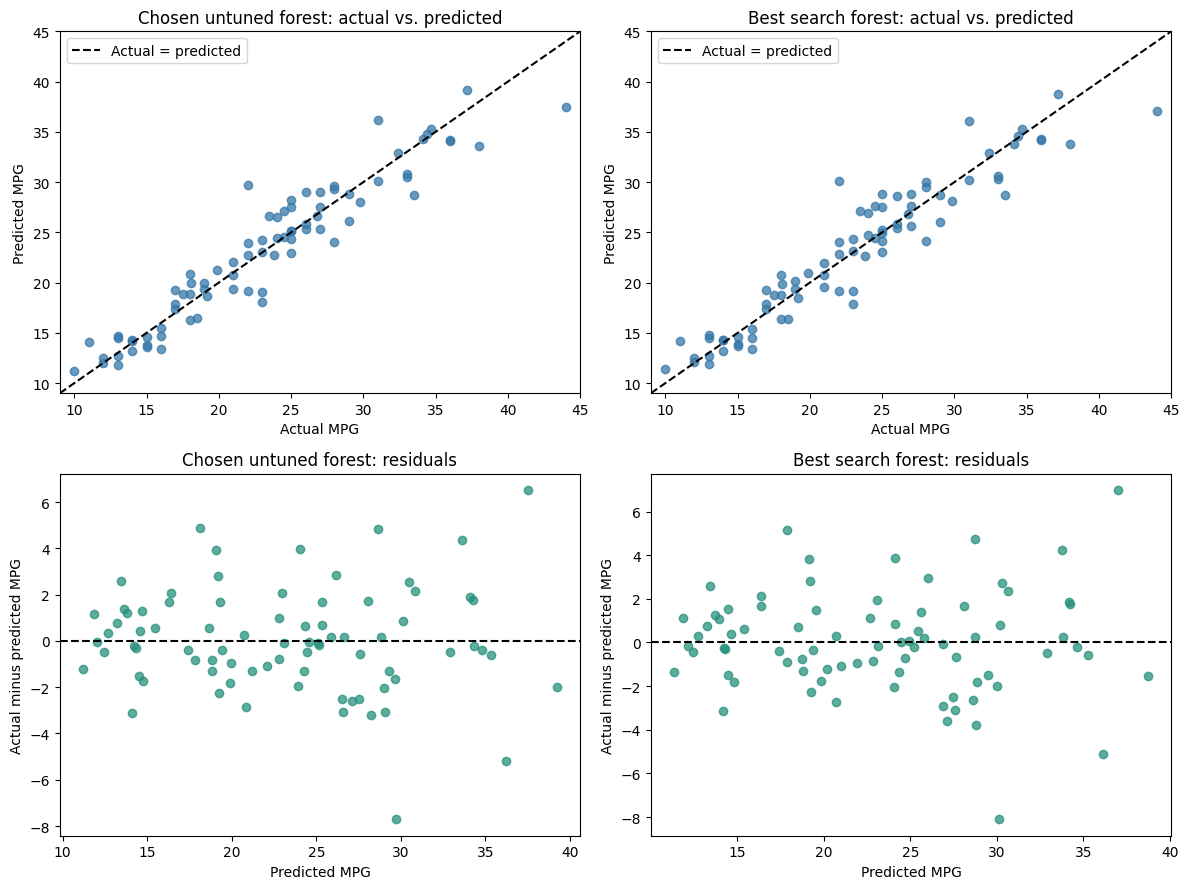

In [111]:
plot_models = ["Chosen untuned forest", "Best search forest"]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
all_values = np.concatenate([y_test.to_numpy()] + [final_predictions[name] for name in plot_models])
lower, upper = all_values.min() - 1, all_values.max() + 1

for column, name in enumerate(plot_models):
    predictions = final_predictions[name]
    residuals = y_test.to_numpy() - predictions

    ax = axes[0, column]
    ax.scatter(y_test, predictions, alpha=0.75, color="#3778A8")
    ax.plot([lower, upper], [lower, upper], "--", color="black", label="Actual = predicted")
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_title(name + ": actual vs. predicted")
    ax.set_xlabel("Actual MPG")
    ax.set_ylabel("Predicted MPG")
    ax.legend()

    ax = axes[1, column]
    ax.scatter(predictions, residuals, alpha=0.75, color="#27917D")
    ax.axhline(0, linestyle="--", color="black")
    ax.set_title(name + ": residuals")
    ax.set_xlabel("Predicted MPG")
    ax.set_ylabel("Actual minus predicted MPG")

fig.tight_layout()
plt.show()

### Descriptive checks on the frozen predictions

From the plots, most predictions are near the diagonal. Errors appear smaller at low MPG and more spread out at higher predicted MPG, without a clear, consistent direction of over- or underprediction. The band table below supports this impression, but the highest band contains few vehicles. These are descriptive observations, not a fitted error model or a formal bias test.

Some high-actual-MPG cases receive less extreme predictions. Averaging across tree leaves is a plausible contributor, rather than a demonstrated cause of any individual error or a universal property of every noisy predictor.

The final forests use all training vehicles, whereas each CV fit uses only four folds. More training data and variation in the 80-vehicle holdout are possible contributors to the CV/test difference; this comparison does not isolate their effects.

The percentile bootstrap below resamples the existing test absolute errors 20,000 times with seed 42. Its 95% interval describes test-sample uncertainty conditional on the fitted model, assuming these test vehicles represent independent draws. It does not include retraining, feature selection, or tuning uncertainty. All checks reuse stored predictions and do not change the model.

In [112]:
predicted_mpg_bins = [-np.inf, 16, 24, 32, np.inf]
predicted_mpg_labels = ["<16", "16–<24", "24–<32", "≥32"]
band_tables = {}
for name in plot_models:
    predictions = final_predictions[name]
    residuals = y_test.to_numpy() - predictions
    diagnostic_rows = pd.DataFrame({
        "Predicted MPG band": pd.cut(
            predictions, bins=predicted_mpg_bins, labels=predicted_mpg_labels, right=False,
        ),
        "residual": residuals,
        "absolute_error": np.abs(residuals),
    })
    band_tables[name] = diagnostic_rows.groupby("Predicted MPG band", observed=True).agg(
        Vehicles=("residual", "size"),
        MAE_MPG=("absolute_error", "mean"),
        Mean_residual_MPG=("residual", "mean"),
    )
residual_band_summary = pd.concat(band_tables, names=["Model"])
display(residual_band_summary.round(2))

cv_fit_sizes = [len(fit_indices) for fit_indices, _ in cv.split(X_train_selected)]
fixed_absolute_errors = np.abs(y_test.to_numpy() - final_predictions["Chosen untuned forest"])
bootstrap_rng = np.random.default_rng(42)
bootstrap_indices = bootstrap_rng.integers(
    0, len(fixed_absolute_errors), size=(20_000, len(fixed_absolute_errors)),
)
bootstrap_mae = fixed_absolute_errors[bootstrap_indices].mean(axis=1)
test_mae_interval = np.quantile(bootstrap_mae, [0.025, 0.975])
contains_cv = test_mae_interval[0] <= original_mae.mean() <= test_mae_interval[1]
display(Markdown(
    f"**Computed sample-size and uncertainty summary:** Final fit: "
    f"**{len(X_train_selected)} vehicles**; CV fits: "
    f"**{min(cv_fit_sizes)}–{max(cv_fit_sizes)} vehicles**; holdout: "
    f"**{len(y_test)} vehicles**. The chosen forest's percentile-bootstrap "
    f"95% MAE interval is approximately **{test_mae_interval[0]:.2f}–"
    f"{test_mae_interval[1]:.2f} MPG**. It "
    f"{'contains' if contains_cv else 'does not contain'} the primary CV mean MAE "
    f"of **{original_mae.mean():.2f} MPG**. This descriptive comparison is "
    f"not a test of development overfitting."
))

Vehicles  MAE_MPG  Mean_residual_MPG
Model                 Predicted MPG band                                      
Chosen untuned forest <16                       17     1.08               0.06
                      16–<24                    24     1.57               0.17
                      24–<32                    29     1.89              -0.34
                      ≥32                       10     2.35               0.56
Best search forest    <16                       17     1.09               0.04
                      16–<24                    23     1.55               0.28
                      24–<32                    30     1.98              -0.48
                      ≥32                       10     2.30               0.72

**Computed sample-size and uncertainty summary:** Final fit: **318 vehicles**; CV fits: **254–255 vehicles**; holdout: **80 vehicles**. The chosen forest's percentile-bootstrap 95% MAE interval is approximately **1.37–2.02 MPG**. It contains the primary CV mean MAE of **2.01 MPG**. This descriptive comparison is not a test of development overfitting.

### Ten largest absolute errors (Part 22)

The table includes the actual MPG, predicted MPG, signed residual, absolute error, and all six original input features. Its row index identifies a record in this dataset; it is not a vehicle name or an additional input feature.

We report the ten largest errors for the selected forest and for the assignment-required search model. The two cases below distinguish **observations** from the table from **hypotheses** about possible explanations.

In [113]:
test_error_tables = {}
for name in plot_models:
    errors = X_test_selected.copy()
    errors.insert(0, "actual_mpg", y_test)
    errors.insert(1, "predicted_mpg", final_predictions[name])
    errors.insert(2, "residual", errors["actual_mpg"] - errors["predicted_mpg"])
    errors.insert(3, "absolute_error", errors["residual"].abs())
    test_error_tables[name] = errors.sort_values("absolute_error", ascending=False)
    print(name + ": ten largest errors")
    display(test_error_tables[name].head(10).round(3))

print(f"Training MPG range: {y_train.min():.1f} to {y_train.max():.1f}")
print(f"Test MPG range: {y_test.min():.1f} to {y_test.max():.1f}")

# Preserve the prediction/error values for review without generating new predictions.
final_review_snapshot = {
    "metrics": final_test_metrics.to_dict(orient="index"),
    "cv_test_comparison": cv_test_comparison.to_dict(orient="index"),
    "largest_errors": {
        name: table.head(10).reset_index().to_dict(orient="records")
        for name, table in test_error_tables.items()
    },
}
print("Final predictions are fixed; no model changes follow from these diagnostics.")

# Reuse fixed predictions; recompute facts instead of hard-coding error order or values.
for case_index in [389, 394]:
    record = test_error_tables["Chosen untuned forest"].loc[case_index]
    direction = "underpredicted" if record["residual"] > 0 else "overpredicted"
    case_rank = test_error_tables["Chosen untuned forest"].index.get_loc(case_index) + 1
    display(Markdown(
        f"**Computed observation — row {case_index} ({direction}; error rank {case_rank}):** "
        f"Actual **{record['actual_mpg']:.1f} MPG**, predicted "
        f"**{record['predicted_mpg']:.2f} MPG**, residual "
        f"**{record['residual']:+.2f} MPG**. Inputs include "
        f"{record['cylinders']:.0f} cylinders, {record['horsepower']:.0f} horsepower, "
        f"weight {record['weight']:,.0f}, and model year {record['model-year']:.0f}."
    ))
    companion = test_error_tables["Best search forest"].loc[case_index]
    companion_rank = test_error_tables["Best search forest"].index.get_loc(case_index) + 1
    display(Markdown(
        f"For the assignment-required search model, this record has prediction "
        f"**{companion['predicted_mpg']:.2f} MPG**, residual "
        f"**{companion['residual']:+.2f} MPG**, and error rank **{companion_rank}**."
    ))

Chosen untuned forest: ten largest errors


,actual_mpg,predicted_mpg,residual,absolute_error,cylinders,displacement,horsepower,weight,acceleration,model-year
389,22.0,29.707,-7.707,7.707,6,232.0,112.0,2835,14.7,82
394,44.0,37.492,6.508,6.508,4,97.0,52.0,2130,24.6,82
377,31.0,36.187,-5.187,5.187,4,91.0,68.0,1970,17.6,82
298,23.0,18.121,4.879,4.879,8,350.0,125.0,3900,17.4,79
238,33.5,28.674,4.826,4.826,4,98.0,83.0,2075,15.9,77
383,38.0,33.628,4.372,4.372,4,91.0,67.0,1965,15.0,82
30,28.0,24.041,3.959,3.959,4,140.0,90.0,2264,15.5,71
101,23.0,19.070,3.930,3.930,6,198.0,95.0,2904,16.0,73
386,25.0,28.222,-3.222,3.222,6,181.0,110.0,2945,16.4,82
124,11.0,14.131,-3.131,3.131,8,350.0,180.0,3664,11.0,73


Best search forest: ten largest errors


,actual_mpg,predicted_mpg,residual,absolute_error,cylinders,displacement,horsepower,weight,acceleration,model-year
389,22.0,30.099,-8.099,8.099,6,232.0,112.0,2835,14.7,82
394,44.0,37.026,6.974,6.974,4,97.0,52.0,2130,24.6,82
298,23.0,17.850,5.150,5.150,8,350.0,125.0,3900,17.4,79
377,31.0,36.127,-5.127,5.127,4,91.0,68.0,1970,17.6,82
238,33.5,28.760,4.740,4.740,4,98.0,83.0,2075,15.9,77
383,38.0,33.779,4.221,4.221,4,91.0,67.0,1965,15.0,82
30,28.0,24.142,3.858,3.858,4,140.0,90.0,2264,15.5,71
101,23.0,19.161,3.839,3.839,6,198.0,95.0,2904,16.0,73
386,25.0,28.796,-3.796,3.796,6,181.0,110.0,2945,16.4,82
341,23.5,27.118,-3.618,3.618,6,173.0,110.0,2725,12.6,81


Training MPG range: 9.0 to 46.6
Test MPG range: 10.0 to 44.0
Final predictions are fixed; no model changes follow from these diagnostics.


**Computed observation — row 389 (overpredicted; error rank 1):** Actual **22.0 MPG**, predicted **29.71 MPG**, residual **-7.71 MPG**. Inputs include 6 cylinders, 112 horsepower, weight 2,835, and model year 82.

For the assignment-required search model, this record has prediction **30.10 MPG**, residual **-8.10 MPG**, and error rank **1**.

**Computed observation — row 394 (underpredicted; error rank 2):** Actual **44.0 MPG**, predicted **37.49 MPG**, residual **+6.51 MPG**. Inputs include 4 cylinders, 52 horsepower, weight 2,130, and model year 82.

For the assignment-required search model, this record has prediction **37.03 MPG**, residual **+6.97 MPG**, and error rank **2**.

### Final interpretation and error-case hypotheses

The chosen untuned forest performed well. Its test MAE was lower than its CV MAE, and it substantially outperformed the mean baseline, reducing absolute error by more than two-thirds. The search forest was slightly worse on the test set, consistent with the development result that tuning did not help. This ordering assesses the choices already fixed before testing; it does not select the final model.

The holdout does not show deterioration relative to CV. A different mix of vehicles, the larger final training set, and uncertainty in the 80-vehicle holdout are possible contributors to the lower test error. The comparison does not isolate a cause or prove that development selection introduced no overfitting. The residuals and largest-error tables show that the model is strong overall but not uniformly accurate.

**Row 389:** The observation is that the six-cylinder, model-year-82 vehicle was overpredicted, with the actual and predicted MPG and negative residual reported above. My hypothesis is that the forest relied heavily on the recent model year and relatively low weight for a six-cylinder vehicle to predict better fuel economy. Missing factors such as gearing, transmission, engine design, or condition could help explain the lower observed MPG.

**Row 394:** The observation is that the light, low-power four-cylinder vehicle was underpredicted, with the actual and predicted MPG and positive residual reported above. My hypothesis is that the forest averaged this unusually efficient case toward less extreme MPG values. Unmeasured fuel type, transmission, aerodynamics, or gearing could help explain its higher observed MPG.

These are possible explanations, not demonstrated causes. The dataset does not establish those missing attributes for either vehicle, and no individual feature has been shown to cause either error.

## 14. Conclusion and AI reflection (Part 24)

### AI reflection

**Use of AI:** AI helped generate and debug code and draft or edit parts of the written explanations, including this reflection. I reviewed the responses and used the clarifications and corrections to refine the analysis. The explanations combine my reasoning with AI-assisted drafting and editing; they were not written entirely independently of AI.

I asked AI to break the assignment into steps and help me understand the purpose of the experiments. It helped suggest four interpretable ratios, explain the two importance methods, organize feature-subset comparisons, and construct a manageable randomized search. I accepted testing all four ratios because each had a reasonable meaning, but I did not assume they would improve prediction. We compared the original and engineered representations with the same untuned forest settings, training-data CV folds, and MAE metric, with median imputation fitted within each fold. The combined feature experiment showed essentially unchanged error. I then proposed removing power-to-weight from the full set and adding it alone to the original six, followed by repeated CV to examine sensitivity to the partitions. The differences were small, so I chose the original six. Four inputs were also defensible under the practical yardstick, but I kept the original measured representation and its lower observed error. The planned hyperparameter search did not show a practically meaningful improvement, and I selected the untuned forest before looking at test results.

I did not retain **any of the four engineered ratios** in the final model. Power-to-weight was the suggestion examined most directly through both addition and removal comparisons. I accepted testing it, but the comparisons did not show enough incremental benefit to justify keeping it. I also modified the AI-assisted explanation that its weak importance reflected redundancy. Training correlations support overlap hypotheses for some displacement-based ratios, and power-to-weight is associated with acceleration and horsepower. These associations make overlap plausible without establishing predictive redundancy or explaining the ablation result. I changed the conclusion to say that the tested ratio added little predictive benefit under these settings, without claiming that we had proved why.

The training-only descriptive check added during the final review also challenged my initial directional guesses: power per displacement was positively associated with MPG, and power-to-weight was not the strongest negative association. Those findings describe these vehicles; they do not establish causal effects or show whether adding the ratios improves the forest. This project showed me that AI suggestions and my own predictions need evidence: meaningful formulas, low importance, and more tuning do not automatically produce a better model.

### Final workflow reflection (Part 25)

I began by inspecting the data and creating the fixed train/test split. The mean predictor established what could be achieved without vehicle features, while the untuned Random Forest supplied the reference for deciding whether later changes improved this model. Without that baseline, a later score would not tell me whether feature engineering or tuning helped.

I engineered interpretable ratios before selecting inputs, so I would not discard raw ingredients before considering their combinations. For example, discarding cylinders entirely would prevent constructing displacement per cylinder. This illustrates the workflow's logic; cylinders did not actually have low importance in our results. I evaluated the expanded representation with the same training-data CV procedure, keeping the comparison fair.

Next, built-in and validation permutation importance suggested hypotheses about which inputs might be removable. Importance could not answer that question by itself, so I retrained and compared candidate subsets using CV and paired fold differences. I considered accuracy, variability, and simplicity, then froze the original six features. Fixing the features before randomized search kept the representation stable while the hyperparameter settings changed, so the tuning comparison had a clear meaning. I compared the search winner with the untuned baseline and selected the untuned forest before testing.

**After creating the split, the final test set stayed out of modeling decisions and evaluation throughout Parts 3–18, including the training-only additional experiment in Part 23.** Feature engineering decisions, importance analysis, feature selection, and tuning all used training data. The assignment-required initial inspection, descriptive statistics, and MPG histogram used all 398 rows before splitting; no modeling decision used the test rows. The retrospective directional-correlation check uses training data only and does not revise the frozen model choices.

Only at Part 19 did I evaluate the fixed forests and mean baseline on the test set. Parts 20–22 reused those stored predictions for plots, residuals, and error cases. The order keeps the final test results from steering model development and gives each stage a clear comparison. The follow-up CV hypothesis was informed by the pilot comparison, its folds are dependent, and the forest seed remained fixed. I therefore treat it as a sensitivity check, and repeated development comparisons may still make CV results optimistic. The later test diagnostics describe the fixed predictions and do not justify changing the model. Additional complexity is worthwhile only when evidence supports a useful improvement; a controlled experiment that finds little benefit is still informative.